# Classical AI: Knowledge Representation and Logic

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising knowledge representation and logic for an exam or interview.
>
> **What you will learn**
> - What a **knowledge-based agent** is: the knowledge base (KB), TELL and ASK, and the *knowledge level*
> - Four classic **representation schemes**: semantic networks, frames, ontologies and production rules (each implemented in a few lines of Python)
> - **Propositional logic**: syntax, semantics, truth tables, validity, satisfiability and entailment
> - Inference algorithms written from scratch: **model checking** (TT-ENTAILS), **CNF conversion**, **resolution**, **forward/backward chaining**, **DPLL** and **WalkSAT**
> - The **Wumpus world**: a logical agent that works out which squares are safe
> - **First-order logic (FOL)**: quantifiers, translating English into FOL, **unification**, generalized modus ponens, forward chaining, Prolog-style backward chaining and FOL resolution
> - The **limits of logic** and the knowledge acquisition bottleneck
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) (functions, dicts, sets, recursion). Helpful: [`01_types_of_ai_and_intelligent_agents.ipynb`](01_types_of_ai_and_intelligent_agents.ipynb) (what an agent is), [`03_informed_search.ipynb`](03_informed_search.ipynb) (search, used by backward chaining and planning).
>
> **Time needed:** about 3 to 4 hours (reading, running, and the practice problems).
>
> **Runs on:** CPU, no API key, no internet. Libraries: Python standard library, pandas, matplotlib, networkx.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Russell & Norvig, *Artificial Intelligence: A Modern Approach* (AIMA, 4th ed.), chapters 7 to 9.

## Explained simply

This notebook is about teaching a computer to **know facts and work out new facts from them**, the way you do in a puzzle. We write down what is true as a list of short statements (the "knowledge base"), and the computer follows strict rules of logic to find out what else must be true. Logic is careful: it only concludes something when it is *certain*, never when it is a guess. That makes it trustworthy, but it also means someone has to type in all the facts first.

- **Everyday example 1:** a detective. "The thief left muddy footprints. Only the gardener had muddy boots today. So the gardener is the thief." If both clues are true, the conclusion cannot be false; nothing is guessed.
- **Everyday example 2:** a family tree app. You type in "Ali is Sara's father" and "Sara is Omar's mother", and the app works out by itself that Ali is Omar's grandfather. You never typed that fact; the app *inferred* it.
- **Tiny example you can follow:** we know two things: (1) "If it is raining, the ground is wet." (2) "It is raining." Then the computer can be **sure** the ground is wet. But if we only know (1) and "the ground is wet", it must **not** conclude that it is raining: a garden sprinkler could have done it. Telling these two cases apart is the heart of logic.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Knowledge base | a list of facts and rules the computer believes | rule engines in banks, knowledge graphs behind search engines |
| Inference | working out new facts that must be true from old ones | family-tree apps, tax software, Prolog programs |
| Logic solver (SAT) | a program that checks whether a set of rules can all be true at once | chip design checks, package installers resolving versions |

## Contents

1. Knowledge-based agents: KB, TELL, ASK and the knowledge level
2. Representation schemes: semantic networks, frames, ontologies, production rules
3. Propositional logic: syntax, semantics and truth tables
4. Validity, satisfiability and entailment; model checking (TT-ENTAILS)
5. Logical equivalences and conversion to CNF
6. Resolution refutation (with a printed proof)
7. Horn clauses, forward chaining and backward chaining
8. SAT solvers: DPLL and WalkSAT
9. The Wumpus world: inferring safe squares
10. First-order logic: objects, predicates, functions, quantifiers
11. Translating English into FOL (and the classic mistakes)
12. Unification
13. Generalized modus ponens and forward chaining in FOL ("Colonel West is a criminal")
14. Backward chaining à la Prolog
15. Resolution in FOL, briefly
16. Limits of logic and the knowledge acquisition bottleneck
17. How this connects to modern AI
18. Recap, practice problems, further reading

In [1]:
# Setup: every library we use in this notebook (all CPU-only, no network).
import itertools                  # products and combinations for enumerating models
import random                     # seeded randomness for random formulas and WalkSAT
import re                         # tiny tokenizer for our logic parser
import time                       # timing comparisons
from collections import deque     # FIFO queues

import matplotlib.pyplot as plt   # plots
import networkx as nx             # graph drawings (semantic network, proof trees)
import pandas as pd               # tables for traces

random.seed(42)                   # make every random choice reproducible
pd.set_option("display.max_colwidth", 120)   # let long formulas show in tables
print("Setup complete. networkx", nx.__version__, "| pandas", pd.__version__)

Setup complete. networkx 3.7 | pandas 2.3.3


## 1. Knowledge-based agents

> **In plain English:** an agent keeps a notebook of facts (the KB), writes new observations into it (TELL) and asks it questions (ASK).

**Intuition.** Think of a new hospital doctor. She carries a notebook of medical facts ("a fever plus a stiff neck suggests meningitis"). Each time she examines a patient she *writes down* what she observed, and then she *asks herself* what follows from everything in the notebook. The notebook is her **knowledge base**; writing is **TELL**; asking is **ASK**.

**Definitions.**
- A **knowledge base (KB)** is a set of **sentences** written in a **knowledge representation language**. Each sentence states something the agent believes about the world.
- **Axioms** are sentences given to the agent directly (not derived).
- **TELL(KB, sentence)** adds a sentence to the KB.
- **ASK(KB, query)** asks whether the query **follows from** (is *entailed by*) the KB. The answer must be produced by **inference**: deriving new sentences from old ones. Crucially, the answer must follow from what was TELLed, not be made up.
- A **knowledge-based agent** runs this loop on every time step *t* (AIMA Fig. 7.1):

```
function KB-AGENT(percept) returns an action
    TELL(KB, MAKE-PERCEPT-SENTENCE(percept, t))     # "at time t I perceived ..."
    action ← ASK(KB, MAKE-ACTION-QUERY(t))           # "what should I do at time t?"
    TELL(KB, MAKE-ACTION-SENTENCE(action, t))       # "at time t I did ..."
    t ← t + 1
    return action
```

**The knowledge level.** Allen Newell (1982) pointed out that we can describe such an agent at two levels:

| Level | Question it answers | Example (a taxi agent) |
|---|---|---|
| **Knowledge level** | *What does the agent know and what are its goals?* | "It knows the Golden Gate Bridge links San Francisco and Marin, and its goal is to reach Marin." |
| **Implementation level** | *How is that knowledge stored and processed?* | "A linked list of strings, or bits in a neural network, searched by a resolution prover." |

If the agent is built correctly we can predict its behaviour at the knowledge level alone ("it knows the bridge goes to Marin and wants to get there, so it will cross the bridge") without caring about the data structures. This is the **declarative** approach: you *tell* the agent what it needs to know and let a general inference procedure work out what to do, rather than writing *procedural* code for every situation.

Below is a minimal KB class. We will plug a real inference engine into ASK in Section 4; for now ASK only looks up stored sentences, which shows the interface.

In [2]:
class TinyKB:
    """A knowledge base with the two standard operations TELL and ASK."""

    def __init__(self):
        self.sentences = []                 # the KB is just a list of sentences

    def tell(self, sentence):
        self.sentences.append(sentence)     # TELL: add a sentence (an axiom or a percept)

    def ask(self, query):
        return query in self.sentences      # ASK: placeholder "inference" = lookup only

kb_demo = TinyKB()
kb_demo.tell("Socrates is a man")                  # an axiom
kb_demo.tell("All men are mortal")                 # another axiom
print("ASK 'Socrates is a man'   ->", kb_demo.ask("Socrates is a man"))
print("ASK 'Socrates is mortal'  ->", kb_demo.ask("Socrates is mortal"))

ASK 'Socrates is a man'   -> True
ASK 'Socrates is mortal'  -> False


**What just happened?** Lookup answered the first question but said `False` to "Socrates is mortal", even though it obviously *follows* from the two sentences. A real knowledge-based agent needs (1) a precise **language** in which "follows from" has a meaning, and (2) an **inference algorithm** that computes it. Building both is the rest of this notebook.

> 🎓 **Exam / interview tip:** "Declarative vs procedural knowledge" is a favourite short question. *Declarative* = facts and rules stated independently of how they are used ("all men are mortal"). *Procedural* = knowledge encoded as steps of a program ("to check mortality, call `is_man()` then return True"). Logic-based KBs are declarative; most practical systems mix both.

## 2. Representation schemes

> **In plain English:** before logic took over, AI stored knowledge as mind-maps, fill-in forms, shared dictionaries and IF-THEN cards.

Before logic became the standard, AI researchers invented several *structured* ways of storing knowledge. They are still everywhere: in knowledge graphs, object-oriented programming, business rule engines and the "schema" of every database.

| Scheme | Core idea | Origin | Modern descendant |
|---|---|---|---|
| **Semantic network** | Concepts are nodes, relations are labelled edges | Quillian (1968) | Knowledge graphs, Wikidata |
| **Frame** | A concept is a record with *slots* (attributes) and *fillers* (values), with defaults and inheritance | Minsky (1974) | Classes and objects in OOP, JSON schemas |
| **Ontology** | A formal, shared vocabulary of classes, properties and constraints | Gruber (1993) defines it as "an explicit specification of a conceptualization" | OWL, RDF, schema.org |
| **Production rules** | IF *condition* THEN *action* rules applied to a working memory | Newell & Simon (1972); expert systems (MYCIN, XCON) | Business rule engines (Drools, CLIPS) |

### 2.1 Semantic networks

**Intuition.** A mind-map. Write "Bird", draw an arrow labelled *is-a* to "Animal", another arrow labelled *can* to "fly".

**Definition.** A **semantic network** is a directed graph whose nodes are concepts (classes or individuals) and whose labelled edges are relations. Two edge labels are special:
- **is-a** (subclass): *Canary is-a Bird*.
- **instance-of** (membership): *Tweety instance-of Canary*.

**Inheritance:** a node inherits every property of the nodes above it along is-a/instance-of edges, *unless* a closer node overrides it (an **exception**). To answer "can Tweety fly?" we walk upwards from Tweety until we find a node that says something about flying.

```
           Animal ──can──► breathe
          /      \
       is-a      is-a
        /          \
     Bird          Mammal ──has──► fur
  (can fly,          |
  has feathers)     is-a
   /      \          |
 is-a    is-a       Bat ──can──► fly
  /        \
Canary   Penguin ──cannot──► fly        (exception!)
  |          |
instance   instance
  |          |
Tweety     Pingu
```

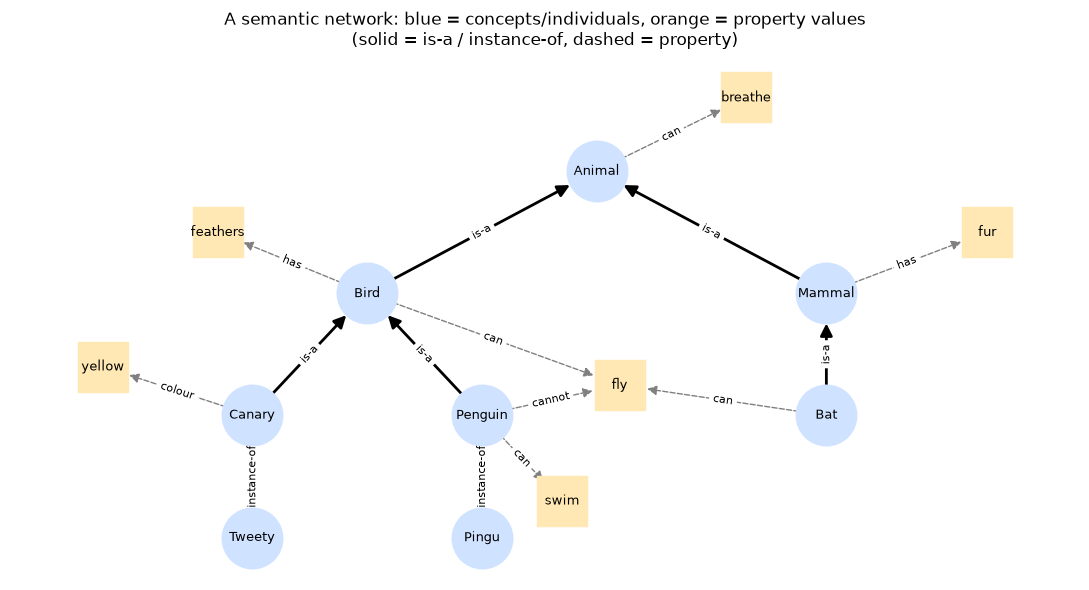

In [3]:
# Build the semantic network as a directed graph with labelled edges.
semnet = nx.DiGraph()
hierarchy = [                                   # (child, parent, label) edges of the taxonomy
    ("Bird", "Animal", "is-a"), ("Mammal", "Animal", "is-a"),
    ("Canary", "Bird", "is-a"), ("Penguin", "Bird", "is-a"), ("Bat", "Mammal", "is-a"),
    ("Tweety", "Canary", "instance-of"), ("Pingu", "Penguin", "instance-of"),
]
properties = [                                  # (concept, value, relation) property edges
    ("Animal", "breathe", "can"), ("Bird", "fly", "can"), ("Bird", "feathers", "has"),
    ("Mammal", "fur", "has"), ("Bat", "fly", "can"), ("Penguin", "fly", "cannot"),
    ("Canary", "yellow", "colour"), ("Penguin", "swim", "can"),
]
for child, parent, label in hierarchy:
    semnet.add_edge(child, parent, label=label, kind="taxonomy")
for concept, value, rel in properties:
    semnet.add_edge(concept, value, label=rel, kind="property")

# Hand-placed coordinates so the picture reads top (general) to bottom (specific).
pos = {"Animal": (0, 3), "Bird": (-2, 2), "Mammal": (2, 2), "Canary": (-3, 1), "Penguin": (-1, 1),
       "Bat": (2, 1), "Tweety": (-3, 0), "Pingu": (-1, 0), "breathe": (1.3, 3.6), "fly": (0.2, 1.25),
       "feathers": (-3.3, 2.5), "fur": (3.4, 2.5), "yellow": (-4.3, 1.4), "swim": (-0.3, 0.3)}
concepts = [n for n in semnet if n in dict.fromkeys([c for c, _, _ in hierarchy] + [p for _, p, _ in hierarchy])]
values = [n for n in semnet if n not in concepts]

fig, ax = plt.subplots(figsize=(11, 6))
nx.draw_networkx_nodes(semnet, pos, nodelist=concepts, node_color="#cfe2ff", node_size=1900, ax=ax)
nx.draw_networkx_nodes(semnet, pos, nodelist=values, node_color="#ffe8b3", node_size=1300, node_shape="s", ax=ax)
nx.draw_networkx_labels(semnet, pos, font_size=9, ax=ax)
tax_edges = [(u, v) for u, v, d in semnet.edges(data=True) if d["kind"] == "taxonomy"]
prop_edges = [(u, v) for u, v, d in semnet.edges(data=True) if d["kind"] == "property"]
nx.draw_networkx_edges(semnet, pos, edgelist=tax_edges, width=2, arrowsize=18, node_size=1900, ax=ax)
nx.draw_networkx_edges(semnet, pos, edgelist=prop_edges, style="dashed", edge_color="gray", arrowsize=14, node_size=1600, ax=ax)
nx.draw_networkx_edge_labels(semnet, pos, edge_labels=nx.get_edge_attributes(semnet, "label"), font_size=8, ax=ax)
ax.set_title("A semantic network: blue = concepts/individuals, orange = property values\n(solid = is-a / instance-of, dashed = property)")
ax.axis("off"); plt.tight_layout(); plt.show()

In [4]:
def ancestors_in_order(net, node):
    """Breadth-first walk up is-a / instance-of edges: nearest ancestors come first."""
    order, frontier, seen = [], deque([node]), {node}
    while frontier:
        n = frontier.popleft()                     # closest unexplored node
        order.append(n)
        for _, parent, d in net.out_edges(n, data=True):
            if d["kind"] == "taxonomy" and parent not in seen:   # follow only hierarchy edges
                seen.add(parent); frontier.append(parent)
    return order

def can(net, node, ability):
    """Inheritance with exceptions: the nearest node that mentions the ability decides."""
    for n in ancestors_in_order(net, node):        # walk from specific to general
        for _, value, d in net.out_edges(n, data=True):
            if value == ability and d["label"] in ("can", "cannot"):
                return d["label"] == "can", n      # answer, and which node decided it
    return False, None                             # nothing known: assume "no"

rows = []
for who in ["Tweety", "Pingu", "Bat", "Canary"]:
    flies, decided_by = can(semnet, who, "fly")
    breathes, b_by = can(semnet, who, "breathe")
    rows.append({"individual/class": who, "path upward": " → ".join(ancestors_in_order(semnet, who)),
                 "can fly?": flies, "decided by": decided_by, "can breathe?": breathes, "(decided by)": b_by})
pd.DataFrame(rows)

,individual/class,path upward,can fly?,decided by,can breathe?,(decided by)
0,Tweety,Tweety → Canary → Bird → Animal,True,Bird,True,Animal
1,Pingu,Pingu → Penguin → Bird → Animal,False,Penguin,True,Animal
2,Bat,Bat → Mammal → Animal,True,Bat,True,Animal
3,Canary,Canary → Bird → Animal,True,Bird,True,Animal


In [5]:
assert can(semnet, "Tweety", "fly") == (True, "Bird")      # inherited from Bird
assert can(semnet, "Pingu", "fly") == (False, "Penguin")   # exception overrides Bird
assert can(semnet, "Bat", "fly") == (True, "Bat")          # a mammal that flies, stated locally
assert can(semnet, "Pingu", "breathe") == (True, "Animal") # inherited two levels up
print("Inheritance checks passed.")

Inheritance checks passed.


**What just happened?** To answer "can Pingu fly?" the program walked Pingu → Penguin and stopped at Penguin, which says *cannot fly*. The more general "Bird can fly" was never reached, so the **specific exception overrode the general default**. "Can Pingu breathe?" had to climb all the way to Animal.

**Complexity.** An inheritance query is a graph walk: O(V + E) time in the worst case, but in practice proportional to the depth of the hierarchy. Space O(V) for the visited set.

> ⚠️ **Common mistake:** confusing **is-a** (a *class* is a subclass of another: Canary ⊆ Bird) with **instance-of** (an *individual* belongs to a class: Tweety ∈ Canary). Early semantic networks blurred the two and got wrong answers, a problem famously criticised in Woods's paper "What's in a link?" (1975). Semantic networks also have no agreed meaning for edges, which is why later work gave them a logical semantics (description logics, then OWL).

### 2.2 Frames

**Intuition.** A form you fill in. A "hotel room" form already has boxes for *beds*, *bathroom*, *price*, and some boxes come pre-filled ("beds: 1 unless stated").

**Definitions.**
- A **frame** is a named data structure describing a stereotyped object or situation.
- A **slot** is an attribute of the frame (e.g. `wheels`); a **filler** is the slot's value (e.g. `4`).
- A **default** filler is assumed unless something more specific overrides it.
- Frames are arranged in an is-a hierarchy and **inherit** slots from their parents.
- A **procedural attachment** (also called a *demon*, or an *if-needed* procedure) is code that computes a filler only when someone asks for it.

```
┌──────── Vehicle ────────┐     ┌──────── Car (is-a Vehicle) ─┐     ┌── my_car (instance-of Car) ──┐
│ wheels:  default 4      │ ◄── │ doors:   default 4          │ ◄── │ colour: red                   │
│ powered: default True   │     │ fuel:    default petrol     │     │ year:   2019                  │
└─────────────────────────┘     └─────────────────────────────┘     │ fuel:   electric (override)   │
                                                                     │ age:    if-needed: 2026-year  │
┌── Motorbike (is-a Vehicle) ─┐                                     └───────────────────────────────┘
│ wheels: 2 (overrides)       │
└─────────────────────────────┘
```

In [6]:
class IfNeeded:
    """A procedural attachment: a function run only when the slot is read."""
    def __init__(self, fn):
        self.fn = fn

class Frame:
    """A frame with named slots, a parent frame and inheritance of fillers."""
    def __init__(self, name, parent=None, **slots):
        self.name, self.parent, self.slots = name, parent, dict(slots)

    def get(self, slot, _origin=None):
        origin = _origin or self                         # the frame the question was asked about
        if slot in self.slots:
            filler = self.slots[slot]
            if isinstance(filler, IfNeeded):             # demon: compute the value on demand
                return filler.fn(origin), f"{self.name} (if-needed)"
            return filler, self.name                     # local (or default) filler
        if self.parent is not None:
            return self.parent.get(slot, origin)         # inherit from the parent frame
        return None, None                                # slot unknown anywhere

CURRENT_YEAR = 2026                                     # fixed so the output never changes
vehicle   = Frame("Vehicle", wheels=4, powered=True)
car       = Frame("Car", vehicle, doors=4, fuel="petrol")
motorbike = Frame("Motorbike", vehicle, wheels=2)
my_car    = Frame("my_car", car, colour="red", year=2019, fuel="electric",
                  age=IfNeeded(lambda f: CURRENT_YEAR - f.get("year")[0]))

rows = []
for frame in [my_car, motorbike]:
    for slot in ["colour", "fuel", "doors", "wheels", "powered", "age"]:
        value, source = frame.get(slot)
        rows.append({"frame": frame.name, "slot": slot, "filler": value, "comes from": source})
frame_table = pd.DataFrame(rows)
frame_table

,frame,slot,filler,comes from
0,my_car,colour,red,my_car
1,my_car,fuel,electric,my_car
2,my_car,doors,4,Car
3,my_car,wheels,4,Vehicle
4,my_car,powered,True,Vehicle
5,my_car,age,7,my_car (if-needed)
6,Motorbike,colour,None,None
7,Motorbike,fuel,None,None
8,Motorbike,doors,None,None
9,Motorbike,wheels,2,Motorbike


In [7]:
assert my_car.get("wheels") == (4, "Vehicle")          # inherited default
assert my_car.get("fuel") == ("electric", "my_car")    # local value overrides Car's default
assert motorbike.get("wheels") == (2, "Motorbike")     # subclass overrides parent's default
assert my_car.get("age")[0] == 7                       # if-needed demon: 2026 - 2019
print("Frame checks passed.")

Frame checks passed.


**What just happened?** `my_car` stores only three things of its own (colour, year, fuel), yet answers questions about doors, wheels and power by inheriting from Car and Vehicle. Its `fuel` slot **overrides** the Car default. The `age` slot holds no number at all: an **if-needed** procedure computed 2026 − 2019 = 7 at query time.

This is exactly how object-oriented classes work (class attributes, subclass overriding, computed properties), which is no coincidence: frames influenced OOP languages.

> 🎓 **Exam / interview tip:** be ready to list the frame vocabulary: *frame, slot, filler, facet* (extra information about a slot, such as its default, type or allowed range), *default, inheritance, procedural attachment (if-needed / if-added demons)*. A standard weakness: with multiple inheritance and defaults, two parents can give conflicting fillers (the "Nixon diamond": Nixon is a Quaker, Quakers are pacifists; Nixon is a Republican, Republicans are not pacifists).

### 2.3 Ontologies

**Intuition.** A shared dictionary *plus* grammar for a domain, agreed by everyone who uses it, so that "Car" in your database and "Car" in mine mean the same thing.

**Definitions.**
- An **ontology** is a formal, explicit specification of the concepts of a domain: its **classes** (Car, Wheel), the **individuals** in them (my_car), the **properties** (relations) between them (`hasPart`, `ownedBy`) and constraints on those properties (*domain* and *range*: `ownedBy` links a Vehicle to a Person).
- Two relations organise most ontologies: **is-a / subClassOf** (taxonomy: every Car is a Vehicle) and **part-of** (mereology: an Engine is part of a Car). Both are **transitive**.
- The **Semantic Web** stores ontologies as **RDF** triples *(subject, predicate, object)*, describes the schema with **RDFS** and the richer **OWL** (Web Ontology Language), all W3C standards, and queries them with **SPARQL**. OWL is based on **description logics**, decidable fragments of first-order logic.
- A **knowledge graph** is a large graph of such triples about real-world entities (Google's Knowledge Graph, Wikidata, DBpedia). The repo covers them in depth in [`08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb).

Here is a tiny ontology in **Turtle**, a common text syntax for RDF (shown as text, not executed):

```turtle
@prefix ex:   <http://example.org/vehicles#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
ex:Car        rdfs:subClassOf ex:Vehicle .
ex:ownedBy    rdfs:domain ex:Vehicle ;  rdfs:range ex:Person .
ex:my_car     a ex:Car ;  ex:colour "red" ;  ex:ownedBy ex:Ayesha .
```

We store the same kind of triples in a Python list and write a mini query engine with variables (written `?x`), which is the core idea of SPARQL.

In [8]:
triples = [
    # taxonomy (is-a, transitive)
    ("Car", "subClassOf", "Vehicle"), ("Truck", "subClassOf", "Vehicle"),
    ("ElectricCar", "subClassOf", "Car"), ("Vehicle", "subClassOf", "Thing"), ("Person", "subClassOf", "Thing"),
    # part-of (transitive)
    ("Engine", "partOf", "Car"), ("Piston", "partOf", "Engine"), ("Wheel", "partOf", "Vehicle"),
    ("Battery", "partOf", "ElectricCar"),
    # property schema: domain and range constraints
    ("ownedBy", "domain", "Vehicle"), ("ownedBy", "range", "Person"),
    # individuals (instance-of) and their facts
    ("my_car", "type", "ElectricCar"), ("van_7", "type", "Truck"), ("old_car", "type", "Car"),
    ("Ayesha", "type", "Person"), ("Bilal", "type", "Person"),
    ("my_car", "ownedBy", "Ayesha"), ("old_car", "ownedBy", "Ayesha"), ("van_7", "ownedBy", "Bilal"),
    ("my_car", "colour", "red"), ("old_car", "colour", "blue"), ("van_7", "colour", "red"),
]

def transitive_closure(rel, start):
    """Everything reachable from `start` by repeatedly following relation `rel`."""
    found, stack = set(), [start]
    while stack:
        x = stack.pop()
        for s, p, o in triples:
            if s == x and p == rel and o not in found:
                found.add(o); stack.append(o)
    return found

def instances_of(cls):
    """Individuals whose type is cls or any subclass of cls (RDFS-style inference)."""
    return sorted(s for s, p, o in triples if p == "type" and (o == cls or cls in transitive_closure("subClassOf", o)))

def parts_of(whole):
    """All parts of `whole`, including parts of parts and parts inherited from superclasses."""
    classes = {whole} | transitive_closure("subClassOf", whole)       # a Car inherits Vehicle's parts
    direct = {s for s, p, o in triples if p == "partOf" and o in classes}
    result = set(direct)
    for part in direct:
        result |= parts_of(part)                                       # part-of is transitive
    return result

def query(patterns, binding=None):
    """Match a list of (s, p, o) patterns; strings starting with '?' are variables."""
    binding = binding or {}
    if not patterns:
        yield dict(binding); return
    first, rest = patterns[0], patterns[1:]
    for triple in triples:
        b = dict(binding)
        ok = True
        for pattern_item, value in zip(first, triple):
            if pattern_item.startswith("?"):
                if b.setdefault(pattern_item, value) != value:     # variable already bound differently
                    ok = False; break
            elif pattern_item != value:                             # constant must match exactly
                ok = False; break
        if ok:
            yield from query(rest, b)

print("Instances of Vehicle (inferred through subClassOf):", instances_of("Vehicle"))
print("Instances of Car:", instances_of("Car"))
print("Parts of ElectricCar (transitive, inherited):", sorted(parts_of("ElectricCar")))
red_and_owner = [(r["?v"], r["?who"]) for r in query([("?v", "colour", "red"), ("?v", "ownedBy", "?who")])]
print("Red vehicles and owners:", red_and_owner)

Instances of Vehicle (inferred through subClassOf): ['my_car', 'old_car', 'van_7']
Instances of Car: ['my_car', 'old_car']
Parts of ElectricCar (transitive, inherited): ['Battery', 'Engine', 'Piston', 'Wheel']
Red vehicles and owners: [('my_car', 'Ayesha'), ('van_7', 'Bilal')]


In [9]:
assert instances_of("Vehicle") == ["my_car", "old_car", "van_7"]
assert parts_of("ElectricCar") == {"Battery", "Engine", "Piston", "Wheel"}
assert sorted(red_and_owner) == [("my_car", "Ayesha"), ("van_7", "Bilal")]

# Use the domain/range schema to check the data (a tiny "reasoner").
def violations():
    bad = []
    for prop in {s for s, p, o in triples if p in ("domain", "range")}:
        dom = next(o for s, p, o in triples if s == prop and p == "domain")
        rng = next(o for s, p, o in triples if s == prop and p == "range")
        for s, p, o in triples:
            if p == prop and s not in instances_of(dom): bad.append((s, p, o, f"subject not a {dom}"))
            if p == prop and o not in instances_of(rng): bad.append((s, p, o, f"object not a {rng}"))
    return bad
print("Schema violations:", violations())
triples.append(("Ayesha", "ownedBy", "van_7"))       # a deliberately wrong fact
print("After adding a wrong fact:", violations())
triples.pop()                                        # remove it again
assert violations() == []

Schema violations:

 []
After adding a wrong fact: [('Ayesha', 'ownedBy', 'van_7', 'subject not a Vehicle'), ('Ayesha', 'ownedBy', 'van_7', 'object not a Person')]


**What just happened?** Nobody wrote "my_car is a Vehicle", yet `instances_of("Vehicle")` found it: the engine **inferred** it through the transitive subClassOf chain ElectricCar → Car → Vehicle. `parts_of` combined *transitivity* (a Piston is part of the Engine, which is part of a Car) with *inheritance* (an ElectricCar is a Car, and every Vehicle has Wheels). The `query` function matched two patterns that share the variable `?v`, just like a SPARQL join. Finally, the schema (domain/range) caught a nonsense fact, "Ayesha ownedBy van_7".

> ⚠️ **Common mistake:** in real RDFS, domain and range are *not* constraints that reject data: an RDFS reasoner would instead **infer** that Ayesha is a Vehicle! Checking data against a schema is done with a separate language such as **SHACL**. Our checker behaves like SHACL, which is what most people intuitively expect.

**Complexity.** Our naive transitive closure scans every triple per step: O(T) per visited node, O(V·T) overall. Real triple stores use indexes on (s, p, o) permutations to make each lookup close to O(log T).

### 2.4 Production rules

**Intuition.** A cook following "IF the water boils THEN add the pasta" cards. She looks at the kitchen (working memory), finds every card whose IF-part is true, picks one, does it, and looks again.

**Definitions.**
- A **production system** has a **working memory** (current facts), a **rule base** of IF *conditions* THEN *actions* rules, and an **inference engine** that repeats the **recognise-act cycle**:
  1. **Match:** find every rule whose conditions all hold. This set is the **conflict set**.
  2. **Conflict resolution:** pick one rule. Common strategies: **refractoriness** (do not fire the same rule on the same facts twice), **specificity** (prefer the rule with more conditions), **recency** (prefer rules matching the newest facts), **priority/order**.
  3. **Act:** execute its actions (add or remove facts).
- The classic expert systems **MYCIN** (diagnosing blood infections, Stanford, 1970s) and **XCON/R1** (configuring DEC VAX computers, 1980s) were production systems. The **Rete** algorithm (Forgy, 1979) made matching fast and is still used in rule engines such as CLIPS and Drools.

Below is the textbook "zoo" identification system (after Winston, *Artificial Intelligence*).

In [10]:
zoo_rules = [   # (name, set of conditions, fact to add)
    ("R1", {"has_hair"}, "mammal"),
    ("R2", {"gives_milk"}, "mammal"),
    ("R3", {"has_feathers"}, "bird"),
    ("R4", {"flies", "lays_eggs"}, "bird"),
    ("R5", {"mammal", "eats_meat"}, "carnivore"),
    ("R6", {"mammal", "pointed_teeth", "claws", "forward_eyes"}, "carnivore"),
    ("R7", {"carnivore", "tawny", "dark_spots"}, "cheetah"),
    ("R8", {"carnivore", "tawny", "black_stripes"}, "tiger"),
    ("R9", {"bird", "does_not_fly", "long_neck", "black_and_white"}, "ostrich"),
    ("R10", {"bird", "swims", "does_not_fly", "black_and_white"}, "penguin"),
]

def run_production_system(rules, memory):
    memory = set(memory)                             # working memory
    fired, trace = set(), []
    cycle = 0
    while True:
        cycle += 1
        conflict_set = [r for r in rules
                        if r[1] <= memory                 # match: all conditions present
                        and r[0] not in fired             # refractoriness: fire each rule once
                        and r[2] not in memory]           # skip rules that add nothing new
        if not conflict_set:
            break                                         # quiescence: nothing left to do
        chosen = max(conflict_set, key=lambda r: len(r[1]))   # specificity: most conditions wins
        memory.add(chosen[2]); fired.add(chosen[0])       # act
        trace.append({"cycle": cycle, "conflict set": [r[0] for r in conflict_set],
                      "fired": chosen[0], "added": chosen[2]})
    return memory, pd.DataFrame(trace)

wm, zoo_trace = run_production_system(zoo_rules, {"has_hair", "gives_milk", "eats_meat", "tawny", "dark_spots"})
assert "cheetah" in wm and "tiger" not in wm
print("Final working memory:", sorted(wm))
zoo_trace

Final working memory: ['carnivore', 'cheetah', 'dark_spots', 'eats_meat', 'gives_milk', 'has_hair', 'mammal', 'tawny']


,cycle,conflict set,fired,added
0,1,"[R1, R2]",R1,mammal
1,2,[R5],R5,carnivore
2,3,[R7],R7,cheetah


**What just happened?** In cycle 1 both R1 and R2 could fire (both conclude *mammal*); conflict resolution picked one and the other was then useless because *mammal* was already known. *mammal* + *eats_meat* enabled R5 (*carnivore*), which enabled R7 (*cheetah*). This "data-driven" style, from facts towards conclusions, is **forward chaining**, which we will define precisely for logic in Section 7.

> 🎓 **Exam / interview tip:** production rules are *not* the same as logical implications. A rule's action can **delete** facts or have side effects (print, call a function), and the result can depend on the conflict-resolution strategy. Logical inference never depends on the order in which rules are tried.

## 3. Propositional logic: syntax, semantics and truth tables

> **In plain English:** propositional logic is maths for true/false statements joined by AND, OR, NOT and IF-THEN.

**Intuition.** Propositional logic is arithmetic for *true/false* statements. Instead of numbers we have **propositions** ("it is raining", written `R`), and instead of + and × we have *and*, *or*, *not*.

### Syntax (what counts as a sentence)

- An **atomic sentence** is a single **proposition symbol** such as `P`, `Q`, `B11`, or the constants `True` and `False`.
- **Complex sentences** are built with five **connectives**:

| Connective | Symbol | Our ASCII | Read as | Example |
|---|---|---|---|---|
| negation | ¬ | `~` | not | ¬W13 ("no wumpus in [1,3]") |
| conjunction | ∧ | `&` | and | P ∧ Q |
| disjunction | ∨ | `\|` | or (inclusive) | P ∨ Q |
| implication | ⇒ | `==>` | if ... then | P ⇒ Q (P is the *premise*, Q the *conclusion*) |
| biconditional | ⇔ | `<=>` | if and only if | B11 ⇔ (P12 ∨ P21) |

- **Precedence**, from tightest to loosest: ¬, ∧, ∨, ⇒, ⇔. So `~A & B | C ==> D` means `((¬A ∧ B) ∨ C) ⇒ D`.
- A **literal** is an atomic sentence or its negation (`P`, `¬P`).

### Semantics (what a sentence means)

- A **model** (also called an *interpretation* or *possible world*) assigns True or False to every proposition symbol.
- The truth value of a complex sentence in a model is computed bottom-up from the truth tables of the connectives. The one people find strange is **implication**: P ⇒ Q is false *only* when P is true and Q is false. "If you score 90%, I'll give you a prize" is not broken if you score 50% and I give you a prize anyway.

To compute with sentences we first need to *read* them. The cell below is a small recursive-descent parser that turns a string into a nested tuple: `"~A & B"` becomes `('and', ('not', 'A'), 'B')`.

In [11]:
TOKEN_RE = re.compile(r"\s*(<=>|==>|[~&|()]|[A-Za-z_][A-Za-z0-9_]*)")   # operators, brackets or symbol names

def tokenize(text):
    """Split a sentence string into tokens, e.g. 'A & ~B' -> ['A', '&', '~', 'B']."""
    tokens, pos, text = [], 0, text.strip()
    while pos < len(text):
        m = TOKEN_RE.match(text, pos)
        if not m:
            raise SyntaxError(f"Unexpected character at position {pos}: {text[pos:]!r}")
        tokens.append(m.group(1)); pos = m.end()
    return tokens

def parse(text):
    """Parse a propositional sentence into nested tuples, respecting precedence ~ & | ==> <=>."""
    tokens, pos = tokenize(text), 0
    def peek():
        return tokens[pos] if pos < len(tokens) else None
    def take(expected=None):
        nonlocal pos
        tok = peek()
        if expected is not None and tok != expected:
            raise SyntaxError(f"Expected {expected!r}, got {tok!r}")
        pos += 1
        return tok
    def p_iff():                                   # loosest: A <=> B
        left = p_implies()
        while peek() == "<=>":
            take(); left = ("iff", left, p_implies())
        return left
    def p_implies():                               # A ==> B (right-associative)
        left = p_or()
        if peek() == "==>":
            take(); return ("implies", left, p_implies())
        return left
    def p_or():                                    # A | B | C  -> ('or', A, B, C)
        parts = [p_and()]
        while peek() == "|":
            take(); parts.append(p_and())
        return parts[0] if len(parts) == 1 else ("or", *parts)
    def p_and():                                   # A & B & C  -> ('and', A, B, C)
        parts = [p_not()]
        while peek() == "&":
            take(); parts.append(p_not())
        return parts[0] if len(parts) == 1 else ("and", *parts)
    def p_not():                                   # tightest: ~A, (A), or a symbol
        if peek() == "~":
            take(); return ("not", p_not())
        if peek() == "(":
            take("("); inner = p_iff(); take(")"); return inner
        tok = take()
        if tok is None or not re.match(r"[A-Za-z_]", tok):
            raise SyntaxError(f"Expected a symbol, got {tok!r}")
        return tok
    result = p_iff()
    if peek() is not None:
        raise SyntaxError(f"Unexpected token {peek()!r}")
    return result

PRETTY = {"and": " ∧ ", "or": " ∨ ", "implies": " ⇒ ", "iff": " ⇔ "}

def show(s, top=True):
    """Pretty-print a parsed sentence with logic symbols."""
    if isinstance(s, str):
        return s
    if s[0] == "not":
        return "¬" + show(s[1], top=False)
    inner = PRETTY[s[0]].join(show(a, top=False) for a in s[1:])
    return inner if top else f"({inner})"

def symbols(s):
    """The set of proposition symbols in a sentence."""
    if isinstance(s, str):
        return set() if s in ("True", "False") else {s}
    return set().union(*(symbols(a) for a in s[1:]))

def pl_true(s, model):
    """Truth value of sentence s in a model (a dict symbol -> bool)."""
    if isinstance(s, str):
        return {"True": True, "False": False}.get(s, model.get(s))
    op, args = s[0], s[1:]
    if op == "not":     return not pl_true(args[0], model)
    if op == "and":     return all(pl_true(a, model) for a in args)
    if op == "or":      return any(pl_true(a, model) for a in args)
    if op == "implies": return (not pl_true(args[0], model)) or pl_true(args[1], model)
    if op == "iff":     return pl_true(args[0], model) == pl_true(args[1], model)
    raise ValueError(f"Unknown operator {op}")

def conj(*parts):
    """Join sentences with AND."""
    return parts[0] if len(parts) == 1 else ("and", *parts)

for text in ["~A & B | C ==> D", "B11 <=> (P12 | P21)", "P ==> Q ==> R"]:
    print(f"{text:22} parses to {parse(text)}\n{'':22} shown as  {show(parse(text))}")
try:
    parse("A & & B")                     # a deliberate syntax error, caught and explained
except SyntaxError as err:
    print("Syntax error caught as expected:", err)

~A & B | C ==> D       parses to ('implies', ('or', ('and', ('not', 'A'), 'B'), 'C'), 'D')
                       shown as  ((¬A ∧ B) ∨ C) ⇒ D
B11 <=> (P12 | P21)    parses to ('iff', 'B11', ('or', 'P12', 'P21'))
                       shown as  B11 ⇔ (P12 ∨ P21)
P ==> Q ==> R          parses to ('implies', 'P', ('implies', 'Q', 'R'))
                       shown as  P ⇒ (Q ⇒ R)
Syntax error caught as expected: Expected a symbol, got '&'


**What just happened?** The parser respected precedence (¬ binds tighter than ∧, which binds tighter than ∨, then ⇒) and treated ⇒ as right-associative, so `P ==> Q ==> R` means P ⇒ (Q ⇒ R). A malformed sentence raised a `SyntaxError`, which we caught on purpose.

Now we can generate truth tables **by code**: list every model (all 2ⁿ combinations of True/False for n symbols) and evaluate each sentence.

In [12]:
def all_models(syms):
    """Yield every model over the given symbols: 2**n dicts."""
    syms = sorted(syms)
    for values in itertools.product([False, True], repeat=len(syms)):
        yield dict(zip(syms, values))

def truth_table(*texts):
    """A pandas truth table with one column per symbol and per sentence."""
    sentences = [parse(t) for t in texts]
    syms = sorted(set().union(*(symbols(s) for s in sentences)))
    rows = []
    for m in all_models(syms):
        row = {k: ("T" if v else "F") for k, v in m.items()}
        for s in sentences:
            row[show(s)] = "T" if pl_true(s, m) else "F"
        rows.append(row)
    return pd.DataFrame(rows)

truth_table("~P", "P & Q", "P | Q", "P ==> Q", "P <=> Q")

,P,Q,¬P,P ∧ Q,P ∨ Q,P ⇒ Q,P ⇔ Q
0,F,F,T,F,F,T,T
1,F,T,T,F,T,T,F
2,T,F,F,F,T,F,F
3,T,T,F,T,T,T,T


This is the standard truth table of the five connectives (compare with AIMA Fig. 7.8). Notice the `P ⇒ Q` column: the only F is in the row P = T, Q = F.

A sentence with more symbols simply gets more rows. The sentence below says "there is a breeze in [1,1] if and only if there is a pit in [1,2] or [2,1]" (we will meet it again in the Wumpus world):

In [13]:
tt_breeze = truth_table("B11 <=> (P12 | P21)")
print("rows =", len(tt_breeze), "= 2^3 models;  models where the sentence is true:",
      (tt_breeze.iloc[:, -1] == "T").sum())
tt_breeze

rows = 8 = 2^3 models;  models where the sentence is true: 4


,B11,P12,P21,B11 ⇔ (P12 ∨ P21)
0,F,F,F,T
1,F,F,T,F
2,F,T,F,F
3,F,T,T,F
4,T,F,F,F
5,T,F,T,T
6,T,T,F,T
7,T,T,T,T


**Complexity.** A truth table over *n* symbols has **2ⁿ rows**; evaluating a sentence of size *s* in one row costs O(s). So the whole table costs **O(s · 2ⁿ)** time. With 30 symbols that is already over a billion rows, which is why we need cleverer algorithms.

## 4. Validity, satisfiability and entailment

> **In plain English:** a fact 'follows' from what we know if it is true in every world that fits what we know; we can check this by trying every world.

**Definitions** (memorise these three, they are exam staples):
- A sentence is **valid** (a **tautology**) if it is true in **every** model. Example: P ∨ ¬P.
- A sentence is **satisfiable** if it is true in **at least one** model. Example: P ∧ Q. A sentence true in no model is **unsatisfiable** (a contradiction): P ∧ ¬P.
- **Entailment**: KB **⊨** α ("KB entails α") means **α is true in every model in which KB is true**. Written with model sets: *M(KB) ⊆ M(α)*.

Two theorems link them (α, β any sentences):
- **Deduction theorem:** α ⊨ β **if and only if** (α ⇒ β) is valid.
- **Refutation (proof by contradiction):** α ⊨ β **if and only if** (α ∧ ¬β) is **unsatisfiable**. Resolution and SAT solvers use this.

| Sentence | valid? | satisfiable? |
|---|---|---|
| P ∨ ¬P | yes | yes |
| P ⇒ Q | no (false when P=T, Q=F) | yes |
| P ∧ ¬P | no | no |
| (P ∧ (P ⇒ Q)) ⇒ Q  (modus ponens) | yes | yes |

**Model checking by enumeration.** The simplest correct inference algorithm, **TT-ENTAILS** (AIMA Fig. 7.10), enumerates every model and checks that α holds wherever KB holds. It is **sound** (only answers yes when KB ⊨ α) and **complete** (always finds the answer) for propositional logic.

In [14]:
def is_valid(s):
    return all(pl_true(s, m) for m in all_models(symbols(s)))          # true in every model

def is_satisfiable(s):
    return any(pl_true(s, m) for m in all_models(symbols(s)))          # true in some model

def tt_entails(kb, alpha):
    """TT-ENTAILS: does kb entail alpha? Returns (answer, number of models checked)."""
    syms = sorted(symbols(kb) | symbols(alpha))
    checked = 0
    def check_all(rest, model):
        nonlocal checked
        if not rest:                               # a complete model: test it
            checked += 1
            if pl_true(kb, model):                 # only models of the KB matter
                return pl_true(alpha, model)       # alpha must also hold here
            return True                            # KB false here: this model is irrelevant
        p, others = rest[0], rest[1:]
        return (check_all(others, {**model, p: True}) and     # try p = True ...
                check_all(others, {**model, p: False}))       # ... and p = False
    return check_all(syms, {}), checked

for text in ["P | ~P", "P ==> Q", "P & ~P", "(P & (P ==> Q)) ==> Q"]:
    s = parse(text)
    print(f"{show(s):24} valid={is_valid(s)!s:5}  satisfiable={is_satisfiable(s)}")

kb_small = parse("(P ==> Q) & P")
for q in ["Q", "~Q", "P | R"]:
    answer, n = tt_entails(kb_small, parse(q))
    print(f"KB = {show(kb_small)}  ⊨  {q:6}?  {answer!s:5}  ({n} models checked)")

P ∨ ¬P                   valid=True   satisfiable=True
P ⇒ Q                    valid=False  satisfiable=True
P ∧ ¬P                   valid=False  satisfiable=False
(P ∧ (P ⇒ Q)) ⇒ Q        valid=True   satisfiable=True
KB = (P ⇒ Q) ∧ P  ⊨  Q     ?  True   (4 models checked)
KB = (P ⇒ Q) ∧ P  ⊨  ~Q    ?  False  (1 models checked)
KB = (P ⇒ Q) ∧ P  ⊨  P | R ?  True   (8 models checked)


In [15]:
# Check the deduction and refutation theorems on random sentences (they must always agree).
rng = random.Random(7)
def random_sentence(depth, syms):
    if depth == 0 or rng.random() < 0.25:
        return rng.choice(syms)
    op = rng.choice(["not", "and", "or", "implies", "iff"])
    if op == "not":
        return ("not", random_sentence(depth - 1, syms))
    return (op, random_sentence(depth - 1, syms), random_sentence(depth - 1, syms))

agree = 0
for _ in range(300):
    a, b = random_sentence(3, list("ABC")), random_sentence(3, list("ABC"))
    e = tt_entails(a, b)[0]
    assert e == is_valid(("implies", a, b))                       # deduction theorem
    assert e == (not is_satisfiable(("and", a, ("not", b))))      # refutation theorem
    agree += 1
print(f"Deduction and refutation theorems confirmed on {agree} random sentence pairs.")

Deduction and refutation theorems confirmed on 300 random sentence pairs.


**What just happened?** From KB = (P ⇒ Q) ∧ P the enumerator proved Q (that is **modus ponens**), refused ¬Q, and proved P ∨ R even though R never appears in the KB (every model of the KB makes P true, so P ∨ R is true there too). The random test confirmed that "KB ⊨ α", "KB ⇒ α is valid" and "KB ∧ ¬α is unsatisfiable" are the same question.

Notice the "models checked" counts. Proving Q took all 4 models over {P, Q}, and P ∨ R all 8 over {P, Q, R}: to say *yes*, every model must be checked. Refusing ¬Q took only 1 model: the very first complete model tried (P = T, Q = T) makes the KB true and ¬Q false, a **counter-model**, and the `and` in `check_all` stops there.

**Complexity of TT-ENTAILS.** Time **O(2ⁿ)** model evaluations (each O(size of KB)); space **O(n)** because the recursion is depth-first. Propositional entailment is **co-NP-complete**, so every known complete algorithm is exponential in the worst case.

> ⚠️ **Common mistake:** "KB ⊨ α" (entailment, a fact about *meaning*) is not the same as "KB ⊢ α" (α can be *derived* by some proof procedure). An inference procedure is **sound** if ⊢ implies ⊨ and **complete** if ⊨ implies ⊢.

Now we can give our `TinyKB` from Section 1 a real ASK:

In [16]:
class PropKB:
    """A propositional knowledge base whose ASK uses truth-table entailment."""
    def __init__(self):
        self.sentences = []
    def tell(self, text):
        self.sentences.append(parse(text))
    def ask(self, text):
        return tt_entails(conj(*self.sentences), parse(text))[0]

socrates = PropKB()
socrates.tell("Man_Socrates")                         # Socrates is a man
socrates.tell("Man_Socrates ==> Mortal_Socrates")     # (propositional version of) all men are mortal
print("ASK Mortal_Socrates  ->", socrates.ask("Mortal_Socrates"))
print("ASK ~Mortal_Socrates ->", socrates.ask("~Mortal_Socrates"))
assert socrates.ask("Mortal_Socrates") and not socrates.ask("~Mortal_Socrates")

ASK Mortal_Socrates  -> True
ASK ~Mortal_Socrates -> False


## 5. Logical equivalences and conversion to CNF

> **In plain English:** many sentences mean the same thing; we rewrite every sentence into one standard shape (an AND of ORs) so a machine can process it.

Two sentences are **logically equivalent** (α ≡ β) if they are true in exactly the same models; equivalently, α ⇔ β is valid. The standard equivalences (AIMA Fig. 7.11) let us rewrite sentences without changing their meaning. We verify each one by code below.

| Name | Equivalence |
|---|---|
| Commutativity | α ∧ β ≡ β ∧ α;  α ∨ β ≡ β ∨ α |
| Associativity | (α ∧ β) ∧ γ ≡ α ∧ (β ∧ γ) (same for ∨) |
| Double negation | ¬¬α ≡ α |
| Contraposition | α ⇒ β ≡ ¬β ⇒ ¬α |
| Implication elimination | α ⇒ β ≡ ¬α ∨ β |
| Biconditional elimination | α ⇔ β ≡ (α ⇒ β) ∧ (β ⇒ α) |
| De Morgan | ¬(α ∧ β) ≡ ¬α ∨ ¬β;  ¬(α ∨ β) ≡ ¬α ∧ ¬β |
| Distributivity | α ∧ (β ∨ γ) ≡ (α ∧ β) ∨ (α ∧ γ);  α ∨ (β ∧ γ) ≡ (α ∨ β) ∧ (α ∨ γ) |

In [17]:
equivalences = {
    "commutativity of ∧":        ("A & B", "B & A"),
    "associativity of ∨":        ("(A | B) | C", "A | (B | C)"),
    "double negation":           ("~~A", "A"),
    "contraposition":            ("A ==> B", "~B ==> ~A"),
    "implication elimination":   ("A ==> B", "~A | B"),
    "biconditional elimination": ("A <=> B", "(A ==> B) & (B ==> A)"),
    "De Morgan (∧)":             ("~(A & B)", "~A | ~B"),
    "De Morgan (∨)":             ("~(A | B)", "~A & ~B"),
    "distributivity ∧ over ∨":   ("A & (B | C)", "(A & B) | (A & C)"),
    "distributivity ∨ over ∧":   ("A | (B & C)", "(A | B) & (A | C)"),
}
rows = []
for name, (lhs, rhs) in equivalences.items():
    ok = is_valid(("iff", parse(lhs), parse(rhs)))          # equivalent  <=>  (lhs <=> rhs) is valid
    rows.append({"law": name, "left": show(parse(lhs)), "right": show(parse(rhs)), "verified by truth table": ok})
    assert ok
# And one famous NON-equivalence: the converse of an implication.
converse_ok = is_valid(("iff", parse("A ==> B"), parse("B ==> A")))
rows.append({"law": "converse (NOT a law!)", "left": "A ⇒ B", "right": "B ⇒ A", "verified by truth table": converse_ok})
pd.DataFrame(rows)

,law,left,right,verified by truth table
0,commutativity of ∧,A ∧ B,B ∧ A,True
1,associativity of ∨,(A ∨ B) ∨ C,A ∨ (B ∨ C),True
2,double negation,¬¬A,A,True
3,contraposition,A ⇒ B,¬B ⇒ ¬A,True
4,implication elimination,A ⇒ B,¬A ∨ B,True
5,biconditional elimination,A ⇔ B,(A ⇒ B) ∧ (B ⇒ A),True
6,De Morgan (∧),¬(A ∧ B),¬A ∨ ¬B,True
7,De Morgan (∨),¬(A ∨ B),¬A ∧ ¬B,True
8,distributivity ∧ over ∨,A ∧ (B ∨ C),(A ∧ B) ∨ (A ∧ C),True
9,distributivity ∨ over ∧,A ∨ (B ∧ C),(A ∨ B) ∧ (A ∨ C),True


> ⚠️ **Common mistake:** "If it rains the grass is wet" does **not** mean "if the grass is wet it rained" (sprinklers exist). The converse B ⇒ A is not equivalent to A ⇒ B; the *contrapositive* ¬B ⇒ ¬A is.

### Conjunctive normal form (CNF)

**Definitions.**
- A **clause** is a disjunction of literals: `¬B11 ∨ P12 ∨ P21`.
- A sentence is in **conjunctive normal form (CNF)** if it is a conjunction of clauses: an AND of ORs.
- **Every** propositional sentence is equivalent to a CNF sentence. The conversion uses the laws above in four steps:
  1. Eliminate ⇔ (biconditional elimination).
  2. Eliminate ⇒ (implication elimination).
  3. Move ¬ inwards (De Morgan, double negation) until it is only applied to symbols.
  4. Distribute ∨ over ∧, and flatten nested ∧ / ∨.

**Worked example by hand** (AIMA §7.5.2): B11 ⇔ (P12 ∨ P21)

| Step | Result |
|---|---|
| 1. eliminate ⇔ | (B11 ⇒ (P12 ∨ P21)) ∧ ((P12 ∨ P21) ⇒ B11) |
| 2. eliminate ⇒ | (¬B11 ∨ P12 ∨ P21) ∧ (¬(P12 ∨ P21) ∨ B11) |
| 3. move ¬ in | (¬B11 ∨ P12 ∨ P21) ∧ ((¬P12 ∧ ¬P21) ∨ B11) |
| 4. distribute | (¬B11 ∨ P12 ∨ P21) ∧ (¬P12 ∨ B11) ∧ (¬P21 ∨ B11) |

In [18]:
def eliminate_iff_implies(s):
    """Steps 1-2: rewrite A<=>B as (~A|B)&(~B|A) and A==>B as ~A|B, recursively."""
    if isinstance(s, str):
        return s
    op, args = s[0], [eliminate_iff_implies(a) for a in s[1:]]
    if op == "iff":
        a, b = args
        return ("and", ("or", ("not", a), b), ("or", ("not", b), a))
    if op == "implies":
        a, b = args
        return ("or", ("not", a), b)
    return (op, *args)

def move_not_inwards(s):
    """Step 3: push negations down to the symbols using De Morgan and double negation."""
    if isinstance(s, str):
        return s
    if s[0] == "not":
        a = s[1]
        if isinstance(a, str):
            return s                                                       # ~P is already a literal
        if a[0] == "not":
            return move_not_inwards(a[1])                                  # ~~A = A
        if a[0] == "and":
            return ("or", *[move_not_inwards(("not", x)) for x in a[1:]])  # ~(A&B) = ~A|~B
        if a[0] == "or":
            return ("and", *[move_not_inwards(("not", x)) for x in a[1:]]) # ~(A|B) = ~A&~B
    return (s[0], *[move_not_inwards(a) for a in s[1:]])

def flatten(s):
    """Merge nested same operators: (A|(B|C)) -> (A|B|C)."""
    if isinstance(s, str) or s[0] == "not":
        return s
    op, out = s[0], []
    for a in s[1:]:
        a = flatten(a)
        out.extend(a[1:] if (not isinstance(a, str) and a[0] == op) else [a])
    return out[0] if len(out) == 1 else (op, *out)

def distribute(s):
    """Step 4: distribute OR over AND until we have an AND of ORs."""
    s = flatten(s)
    if isinstance(s, str) or s[0] == "not":
        return s
    op, args = s[0], [distribute(a) for a in s[1:]]
    if op == "and":
        return flatten(("and", *args))
    for i, a in enumerate(args):                       # op is "or": look for an AND inside it
        if not isinstance(a, str) and a[0] == "and":
            rest = args[:i] + args[i + 1:]
            return distribute(("and", *[("or", c, *rest) for c in a[1:]]))   # (X&Y)|R = (X|R)&(Y|R)
    return flatten(("or", *args))

def to_cnf(s, verbose=False):
    s1 = eliminate_iff_implies(s); s2 = move_not_inwards(s1); s3 = flatten(distribute(s2))
    if verbose:
        for label, x in [("input", s), ("eliminate ⇔ and ⇒", s1), ("move ¬ inwards", s2), ("distribute ∨ over ∧", s3)]:
            print(f"{label:20}: {show(x)}")
    return s3

cnf_breeze = to_cnf(parse("B11 <=> (P12 | P21)"), verbose=True)

input               : B11 ⇔ (P12 ∨ P21)
eliminate ⇔ and ⇒   : (¬B11 ∨ (P12 ∨ P21)) ∧ (¬(P12 ∨ P21) ∨ B11)
move ¬ inwards      : (¬B11 ∨ (P12 ∨ P21)) ∧ ((¬P12 ∧ ¬P21) ∨ B11)
distribute ∨ over ∧ : (¬B11 ∨ P12 ∨ P21) ∧ (¬P12 ∨ B11) ∧ (¬P21 ∨ B11)


For inference it is convenient to store a CNF sentence as a **list of clauses**, each clause a `frozenset` of literal strings (`'P12'`, `'~B11'`). We also drop **tautological** clauses such as `P ∨ ¬P ∨ Q`, which are always true and carry no information.

In [19]:
def lit(l):
    """('not','P') -> '~P';  'P' -> 'P'."""
    return l if isinstance(l, str) else "~" + l[1]

def negate(l):
    return l[1:] if l.startswith("~") else "~" + l

def clauses_of(s):
    """Convert any sentence to a list of clauses (frozensets of literals)."""
    cnf = to_cnf(s)
    conjuncts = cnf[1:] if (not isinstance(cnf, str) and cnf[0] == "and") else [cnf]
    result = []
    for c in conjuncts:
        lits = c[1:] if (not isinstance(c, str) and c[0] == "or") else [c]
        clause = frozenset(lit(x) for x in lits)
        if any(negate(x) in clause for x in clause):     # contains P and ~P: always true, drop it
            continue
        if clause not in result:
            result.append(clause)
    return result

def show_clause(c):
    return "□  (the empty clause)" if not c else " ∨ ".join(sorted(("¬" + x[1:]) if x.startswith("~") else x for x in c))

print([show_clause(c) for c in clauses_of(parse("B11 <=> (P12 | P21)"))])

# Verify: CNF is equivalent to the original on 300 random sentences.
for _ in range(300):
    s = random_sentence(3, list("ABCD"))
    assert all(pl_true(s, m) == pl_true(to_cnf(s), m) for m in all_models(symbols(s)))
print("CNF conversion verified equivalent on 300 random sentences.")

['P12 ∨ P21 ∨ ¬B11', 'B11 ∨ ¬P12', 'B11 ∨ ¬P21']


CNF conversion verified equivalent on 300 random sentences.


**What just happened?** The code reproduced the hand-worked table step by step, then a randomized test confirmed that the CNF form has exactly the same truth value as the original in every model.

**Complexity.** Steps 1 to 3 are linear in the size of the sentence, but step 4 (distribution) can blow up **exponentially**: (A₁ ∧ B₁) ∨ (A₂ ∧ B₂) ∨ … ∨ (Aₙ ∧ Bₙ) has 2ⁿ clauses in CNF. The **Tseitin transformation** avoids this by introducing new symbols, giving an *equisatisfiable* (not equivalent) CNF of linear size; every practical SAT solver uses it.

## 6. Resolution refutation

> **In plain English:** to prove something, assume it is false and keep combining clues until you hit a flat contradiction.

**Intuition.** "Either the butler did it or the cook did it. The cook did not do it. So the butler did it." Two clauses that disagree on one literal can be combined into a new clause that drops that literal.

**Definition (resolution rule).** From two clauses containing **complementary literals** ℓ and ¬ℓ, infer the **resolvent**: the disjunction of all the other literals.

```
   A ∨ B ∨ ℓ        ¬ℓ ∨ C
  ─────────────────────────   resolve on ℓ
         A ∨ B ∨ C
```
Resolving `P` with `¬P` gives the **empty clause □**, which is false: a contradiction.

**Resolution refutation algorithm** (PL-RESOLUTION, AIMA Fig. 7.12), to decide KB ⊨ α:
1. Convert KB ∧ ¬α to CNF clauses.
2. Repeatedly resolve pairs of clauses, adding new resolvents.
3. If the empty clause appears, KB ∧ ¬α is unsatisfiable, so **KB ⊨ α**. If no new clauses can be added, KB does not entail α.

Resolution is **sound** and **refutation-complete** for propositional logic (the *ground resolution theorem*).

**Worked example by hand.** KB = (B11 ⇔ (P12 ∨ P21)) ∧ ¬B11 ("no breeze in [1,1]"), query α = ¬P12 ("no pit in [1,2]").
Clauses of KB ∧ ¬α: {¬B11 ∨ P12 ∨ P21}, {¬P12 ∨ B11}, {¬P21 ∨ B11}, {¬B11}, {P12}.
Resolve {¬P12 ∨ B11} with {P12} → {B11}. Resolve {B11} with {¬B11} → □. Proved.

In [20]:
def resolve(ci, cj):
    """All non-tautological resolvents of two clauses, with the symbol resolved on."""
    out = []
    for l in ci:
        if negate(l) in cj:                                   # complementary pair found
            new = (ci - {l}) | (cj - {negate(l)})             # union of the remaining literals
            if not any(negate(x) in new for x in new):        # skip tautologies like P | ~P
                out.append((frozenset(new), l.lstrip("~")))
    return out

def pl_resolution(kb, alpha, max_clauses=20_000):
    """Resolution refutation. Returns (entailed?, initial clauses, parent map for the proof)."""
    start = clauses_of(conj(kb, ("not", alpha)))              # CNF of KB & ~alpha
    parents = {c: None for c in start}                        # None marks an input clause
    clauses, tried = list(start), set()
    while True:
        new = []
        for i in range(len(clauses)):
            for j in range(i + 1, len(clauses)):
                pair = (clauses[i], clauses[j])
                if pair in tried:                             # never resolve the same pair twice
                    continue
                tried.add(pair)
                for r, on in resolve(*pair):
                    if r not in parents:                      # a genuinely new clause
                        parents[r] = (pair[0], pair[1], on)
                        new.append(r)
                        if not r:                             # the empty clause: contradiction!
                            return True, start, parents
        if not new:                                           # saturation without □
            return False, start, parents
        clauses.extend(new)
        if len(clauses) > max_clauses:
            raise RuntimeError("Resolution produced too many clauses")

def proof_steps(parents, target=frozenset()):
    """Walk back from the empty clause and list only the resolution steps actually used."""
    steps, done = [], set()
    def visit(c):
        if c in done or parents[c] is None:
            return
        a, b, on = parents[c]
        visit(a); visit(b)
        steps.append((a, b, on, c)); done.add(c)
    visit(target)
    return steps

def print_resolution_proof(kb_text, alpha_text):
    kb, alpha = parse(kb_text), parse(alpha_text)
    proved, start, parents = pl_resolution(kb, alpha)
    print(f"KB: {show(kb)}\nQuery α: {show(alpha)}\nClauses of KB ∧ ¬α:")
    for i, c in enumerate(start, 1):
        print(f"   C{i}: {show_clause(c)}")
    if not proved:
        print(f"No empty clause after {len(parents)} clauses: KB does NOT entail α.")
        return proved
    print("Proof:")
    for k, (a, b, on, c) in enumerate(proof_steps(parents), 1):
        print(f"   step {k}: [{show_clause(a)}]  +  [{show_clause(b)}]   resolve on {on}   ⟹  {show_clause(c)}")
    print(f"Empty clause derived: KB ⊨ α.  (Total clauses generated: {len(parents)})")
    return proved

wumpus_mini = "(B11 <=> (P12 | P21)) & ~B11"
assert print_resolution_proof(wumpus_mini, "~P12")

KB: (B11 ⇔ (P12 ∨ P21)) ∧ ¬B11
Query α: ¬P12
Clauses of KB ∧ ¬α:
   C1: P12 ∨ P21 ∨ ¬B11
   C2: B11 ∨ ¬P12
   C3: B11 ∨ ¬P21
   C4: ¬B11
   C5: P12
Proof:
   step 1: [B11 ∨ ¬P12]  +  [P12]   resolve on P12   ⟹  B11
   step 2: [¬B11]  +  [B11]   resolve on B11   ⟹  □  (the empty clause)
Empty clause derived: KB ⊨ α.  (Total clauses generated: 12)


In [21]:
assert print_resolution_proof("(A ==> B) & (B ==> C) & A", "C")       # a two-step chain
print()
assert not print_resolution_proof("(A ==> B) & B", "A")               # affirming the consequent is NOT valid

KB: (A ⇒ B) ∧ (B ⇒ C) ∧ A
Query α: C
Clauses of KB ∧ ¬α:
   C1: B ∨ ¬A
   C2: C ∨ ¬B
   C3: A
   C4: ¬C
Proof:
   step 1: [B ∨ ¬A]  +  [A]   resolve on A   ⟹  B
   step 2: [C ∨ ¬B]  +  [¬C]   resolve on C   ⟹  ¬B
   step 3: [B]  +  [¬B]   resolve on B   ⟹  □  (the empty clause)
Empty clause derived: KB ⊨ α.  (Total clauses generated: 10)

KB: (A ⇒ B) ∧ B
Query α: A
Clauses of KB ∧ ¬α:
   C1: B ∨ ¬A
   C2: B
   C3: ¬A
No empty clause after 3 clauses: KB does NOT entail α.


In [22]:
# Cross-check resolution against truth-table entailment on random KBs and queries.
rng = random.Random(11)
counts = {"entailed": 0, "not entailed": 0}
for _ in range(120):
    kb, alpha = random_sentence(3, list("ABCD")), random_sentence(2, list("ABCD"))
    expected = tt_entails(kb, alpha)[0]
    assert pl_resolution(kb, alpha)[0] == expected, (show(kb), show(alpha))
    counts["entailed" if expected else "not entailed"] += 1
print("Resolution agreed with TT-ENTAILS on all 120 random cases:", counts)

Resolution agreed with TT-ENTAILS on all 120 random cases: {'entailed': 34, 'not entailed': 86}


**What just happened?** The first proof is exactly the two-step hand proof: from ¬P12 ∨ B11 and the negated query P12 we get B11, which clashes with ¬B11. In the second example the query was not entailed: from A ⇒ B and B we cannot conclude A, and resolution saturated without producing □. The randomized test compares resolution with brute-force model checking.

**Complexity.** Over n symbols there are at most 3ⁿ distinct clauses (each symbol is absent, positive or negative), so resolution always terminates, but it can take **exponential** time and space in the worst case (Haken, 1985, proved exponential lower bounds for the pigeonhole formulas).

> 🎓 **Exam / interview tip:** a typical question gives 3 to 5 sentences and asks you to "prove X by resolution". Recipe: (1) **negate the goal** and add it, (2) convert everything to clauses, (3) resolve, each time cancelling one complementary pair, (4) stop at □. Do not forget step 1, and never cancel two pairs at once: resolving P ∨ Q with ¬P ∨ ¬Q gives Q ∨ ¬Q (a tautology), **not** □.

## 7. Horn clauses, forward chaining and backward chaining

> **In plain English:** when every rule looks like 'these facts together give that fact', we can reason very fast, either from facts forward or from the question backward.

General resolution is expensive. Many real KBs only contain a restricted kind of clause, for which inference is **linear time**.

**Definitions.**
- A **definite clause** has **exactly one** positive literal: ¬L ∨ ¬M ∨ P, which is the same as the rule **L ∧ M ⇒ P**. A single positive literal (`A`) is a **fact**.
- A **Horn clause** has **at most one** positive literal. So definite clauses are Horn, and so are **goal clauses** (no positive literal, e.g. ¬A ∨ ¬B, i.e. A ∧ B ⇒ False).
- Rules are written **body ⇒ head**: the body (premise) is a conjunction of symbols, the head (conclusion) one symbol.

**Forward chaining** (data-driven): start from the known facts; whenever all premises of a rule are known, add its head; stop when the query is added or nothing new appears. **Backward chaining** (goal-driven): start from the query; find a rule whose head is the query and recursively prove each premise.

We use the KB of AIMA Fig. 7.16:
```
P ⇒ Q        L ∧ M ⇒ P        B ∧ L ⇒ M        A ∧ P ⇒ L        A ∧ B ⇒ L        A        B
```

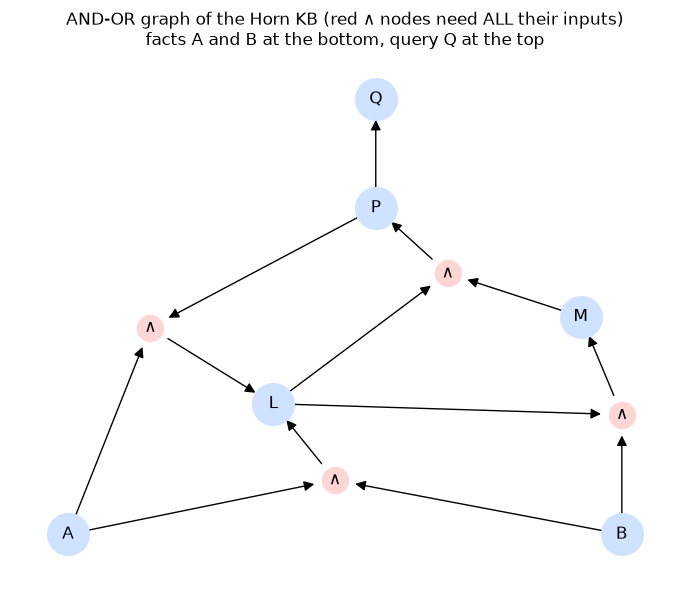

In [23]:
def horn(text):
    """'A & B ==> L'  ->  (['A', 'B'], 'L');   'A'  ->  ([], 'A')  (a fact)."""
    if "==>" in text:
        body, head = text.split("==>")
        return ([b.strip() for b in body.split("&")], head.strip())
    return ([], text.strip())

def horn_to_sentence(rules):
    """Turn Horn rules back into one logic sentence (so we can check them with TT-ENTAILS)."""
    parts = []
    for body, head in rules:
        if body:
            parts.append(("implies", body[0] if len(body) == 1 else ("and", *body), head))
        else:
            parts.append(head)
    return conj(*parts)

horn_kb = [horn(r) for r in ["P ==> Q", "L & M ==> P", "B & L ==> M", "A & P ==> L", "A & B ==> L", "A", "B"]]

# Draw the AND-OR graph: an arc from every premise to a small "AND" node, then to the head.
g = nx.DiGraph()
for i, (body, head) in enumerate(horn_kb):
    if len(body) == 1:
        g.add_edge(body[0], head)                    # a single premise needs no AND node
    elif body:
        and_node = f"∧{i}"
        for b in body:
            g.add_edge(b, and_node)
        g.add_edge(and_node, head)
pos_h = {"Q": (0, 4), "P": (0, 3), "M": (1, 2), "L": (-0.5, 1.2), "A": (-1.5, 0), "B": (1.2, 0),
         "∧1": (0.35, 2.4), "∧2": (1.2, 1.1), "∧3": (-1.1, 1.9), "∧4": (-0.2, 0.5)}
fig, ax = plt.subplots(figsize=(7, 6))
symbol_nodes = [n for n in g if not n.startswith("∧")]
and_nodes = [n for n in g if n.startswith("∧")]
nx.draw_networkx_nodes(g, pos_h, nodelist=symbol_nodes, node_color="#cfe2ff", node_size=900, ax=ax)
nx.draw_networkx_nodes(g, pos_h, nodelist=and_nodes, node_color="#ffd6d6", node_size=350, ax=ax)
nx.draw_networkx_labels(g, pos_h, labels={n: (n if n in symbol_nodes else "∧") for n in g}, ax=ax)
nx.draw_networkx_edges(g, pos_h, arrowsize=15, node_size=900, ax=ax)
ax.set_title("AND-OR graph of the Horn KB (red ∧ nodes need ALL their inputs)\nfacts A and B at the bottom, query Q at the top")
ax.axis("off"); plt.tight_layout(); plt.show()

In [24]:
def pl_fc_entails(rules, q, trace=None):
    """PL-FC-ENTAILS? (AIMA Fig. 7.15): forward chaining with premise counters."""
    count = [len(body) for body, head in rules]           # premises still unproved, per rule
    inferred = set()                                      # symbols already processed
    agenda = deque(head for body, head in rules if not body)   # start with the facts
    while agenda:
        p = agenda.popleft()
        if p == q:
            if trace is not None: trace.append({"pop": p, "action": "query reached", "counts": list(count)})
            return True
        if p in inferred:
            continue
        inferred.add(p)
        fired = []
        for i, (body, head) in enumerate(rules):
            if p in body:
                count[i] -= 1                             # one more premise of rule i is now known
                if count[i] == 0:                         # all premises known: the rule fires
                    agenda.append(head); fired.append(f"{' & '.join(body)} ⇒ {head}")
        if trace is not None:
            trace.append({"pop": p, "action": "fires " + ("; ".join(fired) if fired else "nothing"), "counts": list(count)})
    return False

fc_trace = []
assert pl_fc_entails(horn_kb, "Q", fc_trace)
print("Rule order for the counts column:", [f"{' & '.join(b)} ⇒ {h}" for b, h in horn_kb if b])
pd.DataFrame([{**row, "counts": row["counts"][:5]} for row in fc_trace])

Rule order for the counts column: ['P ⇒ Q', 'L & M ⇒ P', 'B & L ⇒ M', 'A & P ⇒ L', 'A & B ⇒ L']


,pop,action,counts
0,A,fires nothing,"[1, 2, 2, 1, 1]"
1,B,fires A & B ⇒ L,"[1, 2, 1, 1, 0]"
2,L,fires B & L ⇒ M,"[1, 1, 0, 1, 0]"
3,M,fires L & M ⇒ P,"[1, 0, 0, 1, 0]"
4,P,fires P ⇒ Q; A & P ⇒ L,"[0, 0, 0, 0, 0]"
5,Q,query reached,"[0, 0, 0, 0, 0]"


In [25]:
def pl_bc_entails(rules, q, trace=None, depth=0, path=frozenset()):
    """Backward chaining: prove q by proving all premises of some rule with head q."""
    pad = "    " * depth
    if trace is not None: trace.append(f"{pad}goal {q}?")
    if q in path:                                          # q is already being proved higher up: a loop
        if trace is not None: trace.append(f"{pad}  {q} is already on the goal stack: fail this branch (loop check)")
        return False
    for body, head in rules:
        if head != q:
            continue
        if all(pl_bc_entails(rules, b, trace, depth + 1, path | {q}) for b in body):
            if trace is not None:
                trace.append(f"{pad}  ✓ {q}" + (f"   by {' & '.join(body)} ⇒ {q}" if body else "   (fact)"))
            return True
    if trace is not None: trace.append(f"{pad}  ✗ {q} cannot be proved")
    return False

bc_trace = []
assert pl_bc_entails(horn_kb, "Q", bc_trace)
print("\n".join(bc_trace))

goal Q?
    goal P?
        goal L?
            goal A?
              ✓ A   (fact)
            goal P?
              P is already on the goal stack: fail this branch (loop check)
            goal A?
              ✓ A   (fact)
            goal B?
              ✓ B   (fact)
          ✓ L   by A & B ⇒ L
        goal M?
            goal B?
              ✓ B   (fact)
            goal L?
                goal A?
                  ✓ A   (fact)
                goal P?
                  P is already on the goal stack: fail this branch (loop check)
                goal A?
                  ✓ A   (fact)
                goal B?
                  ✓ B   (fact)
              ✓ L   by A & B ⇒ L
          ✓ M   by B & L ⇒ M
      ✓ P   by L & M ⇒ P
  ✓ Q   by P ⇒ Q


In [26]:
# Check forward and backward chaining against truth-table entailment for every symbol (and an unknown one).
horn_sentence = horn_to_sentence(horn_kb)
rows = []
for q in ["A", "B", "L", "M", "P", "Q", "Z"]:
    tt = tt_entails(horn_sentence, q)[0]
    fc, bc = pl_fc_entails(horn_kb, q), pl_bc_entails(horn_kb, q)
    assert fc == bc == tt
    rows.append({"query": q, "TT-ENTAILS": tt, "forward chaining": fc, "backward chaining": bc})
# A second Horn KB where something is NOT derivable.
kb2 = [horn(r) for r in ["A & B ==> C", "C ==> D", "E ==> F", "A", "E"]]
for q in ["C", "D", "F", "B"]:
    tt = tt_entails(horn_to_sentence(kb2), q)[0]
    assert pl_fc_entails(kb2, q) == pl_bc_entails(kb2, q) == tt
    rows.append({"query": f"{q} (KB2)", "TT-ENTAILS": tt, "forward chaining": pl_fc_entails(kb2, q), "backward chaining": pl_bc_entails(kb2, q)})
pd.DataFrame(rows)

,query,TT-ENTAILS,forward chaining,backward chaining
0,A,True,True,True
1,B,True,True,True
2,L,True,True,True
3,M,True,True,True
4,P,True,True,True
5,Q,True,True,True
6,Z,False,False,False
7,C (KB2),False,False,False
8,D (KB2),False,False,False
9,F (KB2),True,True,True


**What just happened?**
- **Forward chaining** popped A and B (the facts). Once both were known the counter of A ∧ B ⇒ L hit zero, so L was added; L and B then fired B ∧ L ⇒ M; L and M fired L ∧ M ⇒ P; P fired P ⇒ Q and the query was reached. Each rule's counter only ever goes down, so every rule is touched a bounded number of times.
- **Backward chaining** started at Q and worked *down*. While proving L it first tried A ∧ P ⇒ L, but P was already an open goal on the stack, so the loop check cut that branch and it used A ∧ B ⇒ L instead.
- Both agree with TT-ENTAILS on every query, including the ones that are not entailed.

| | Forward chaining | Backward chaining |
|---|---|---|
| Direction | data-driven (facts → query) | goal-driven (query → facts) |
| Time | **O(size of KB)**, linear | often much less than linear: touches only relevant rules (worst case linear with memoization; our simple version may repeat sub-proofs) |
| Good for | monitoring, deriving *everything* that follows | answering a specific question ("why?", diagnosis) |
| Sound and complete for | Horn (definite clause) KBs | Horn (definite clause) KBs |
| Used in | production systems, Datalog engines | Prolog, expert-system consultation |

> ⚠️ **Common mistake:** forward and backward chaining are only **complete for Horn KBs**. Faced with a disjunction such as P ∨ Q (two positive literals) they cannot reason by cases; you need resolution or a SAT solver.

## 8. SAT solvers: DPLL and WalkSAT

> **In plain English:** a SAT solver is a smart guess-and-check machine that finds a way to make all the rules true, or proves there is none.

**The SAT problem:** given a CNF sentence, is it satisfiable, and if so, find a model. SAT was the **first problem proved NP-complete** (Cook, 1971, and independently Levin). Entailment reduces to it: KB ⊨ α iff KB ∧ ¬α is *unsatisfiable*.

### DPLL (Davis-Putnam-Logemann-Loveland, 1962)

DPLL is a depth-first backtracking search over partial models, much faster than truth tables thanks to three ideas:
1. **Early termination:** a clause is true as soon as *one* literal is true; the sentence is false as soon as *one* clause is false. No need to assign every symbol.
2. **Pure symbol heuristic:** if a symbol appears with only one sign in the not-yet-satisfied clauses (always positive, or always negative), set it to make those literals true. This can never hurt.
3. **Unit clause heuristic:** if a clause has only one unassigned literal and the rest are false, that literal *must* be true. Assigning it can create new unit clauses (**unit propagation**).

Modern solvers (CDCL: conflict-driven clause learning) add clause learning, non-chronological backjumping, restarts and the "two watched literals" data structure, and routinely solve industrial instances with millions of variables.

In [27]:
def clause_value(clause, model):
    """True if some literal is true, False if all literals are false, None if still undecided."""
    undecided = False
    for l in clause:
        s = l.lstrip("~")
        if s in model:
            if model[s] != l.startswith("~"):      # literal is true under the partial model
                return True
        else:
            undecided = True
    return None if undecided else False

def find_pure_symbol(syms, clauses, model):
    for s in syms:
        pos = neg = False
        for c in clauses:
            if clause_value(c, model) is True:      # ignore clauses that are already satisfied
                continue
            pos |= s in c
            neg |= ("~" + s) in c
        if pos != neg:                              # appears with exactly one sign
            return s, pos
    return None, None

def find_unit_clause(clauses, model):
    for c in clauses:
        if clause_value(c, model) is not None:      # already true or already false
            continue
        unassigned = [l for l in c if l.lstrip("~") not in model]
        if len(unassigned) == 1:                    # every other literal is false: forced
            l = unassigned[0]
            return l.lstrip("~"), not l.startswith("~")
    return None, None

def dpll(clauses, syms, model, stats):
    stats["calls"] += 1
    values = [clause_value(c, model) for c in clauses]
    if all(v is True for v in values):              # every clause satisfied: model found
        return model
    if any(v is False for v in values):             # some clause falsified: backtrack
        return None
    p, val = find_pure_symbol(syms, clauses, model)
    if p is not None:
        stats["pure"] += 1
        return dpll(clauses, [s for s in syms if s != p], {**model, p: val}, stats)
    p, val = find_unit_clause(clauses, model)
    if p is not None:
        stats["unit"] += 1
        return dpll(clauses, [s for s in syms if s != p], {**model, p: val}, stats)
    p, rest = syms[0], syms[1:]                     # no shortcut applies: branch on p
    stats["branches"] += 1
    return (dpll(clauses, rest, {**model, p: True}, stats) or
            dpll(clauses, rest, {**model, p: False}, stats))

def dpll_satisfiable(clauses):
    syms = sorted({l.lstrip("~") for c in clauses for l in c})
    stats = {"calls": 0, "pure": 0, "unit": 0, "branches": 0}
    return dpll(list(clauses), syms, {}, stats), stats

def dpll_entails(kb, alpha):
    """KB |= alpha  iff  KB & ~alpha is unsatisfiable."""
    model, _ = dpll_satisfiable(clauses_of(conj(kb, ("not", alpha))))
    return model is None

example = clauses_of(parse("(A | B) & (~A | C) & (~B | ~C) & (A | ~C)"))
model, stats = dpll_satisfiable(example)
print("Clauses:", [show_clause(c) for c in example])
print("DPLL model:", model, "| stats:", stats)
assert all(clause_value(c, model) for c in example)

Clauses:

 ['A ∨ B', 'C ∨ ¬A', '¬B ∨ ¬C', 'A ∨ ¬C']
DPLL model: {'A': True, 'B': False, 'C': True} | stats: {'calls': 4, 'pure': 2, 'unit': 0, 'branches': 1}


In [28]:
def random_3cnf(n_vars, n_clauses, rng):
    """A random 3-CNF formula: each clause has 3 distinct symbols with random signs."""
    syms = [f"X{i}" for i in range(n_vars)]
    return [frozenset(("~" if rng.random() < 0.5 else "") + s for s in rng.sample(syms, 3)) for _ in range(n_clauses)]

def brute_force_sat(clauses):
    syms = sorted({l.lstrip("~") for c in clauses for l in c})
    return any(all(clause_value(c, m) for c in clauses) for m in all_models(syms))

rng = random.Random(3)
for trial in range(40):                               # DPLL must agree with brute force
    f = random_3cnf(8, rng.randint(10, 50), rng)
    m, _ = dpll_satisfiable(f)
    assert (m is not None) == brute_force_sat(f)
    if m is not None:
        assert all(clause_value(c, m) for c in f)     # and any model it returns must be real
print("DPLL agreed with brute-force satisfiability on 40 random 3-CNF formulas.")

# Entailment via DPLL must agree with TT-ENTAILS too.
rng = random.Random(5)
for _ in range(150):
    kb, alpha = random_sentence(3, list("ABCD")), random_sentence(2, list("ABCD"))
    assert dpll_entails(kb, alpha) == tt_entails(kb, alpha)[0]
print("DPLL entailment agreed with TT-ENTAILS on 150 random cases.")

DPLL agreed with brute-force satisfiability on 40 random 3-CNF formulas.


DPLL entailment agreed with TT-ENTAILS on 150 random cases.


### The satisfiability threshold

For random 3-CNF formulas with *n* symbols and *m* clauses, almost all formulas are satisfiable when the ratio m/n is small and almost none when it is large. The switch happens sharply near **m/n ≈ 4.27**, and the hardest instances for solvers sit right at the threshold. Let's see it with our own DPLL (small n, so the curve is softer than the asymptotic one).

Solved 200 formulas in 6.5 s


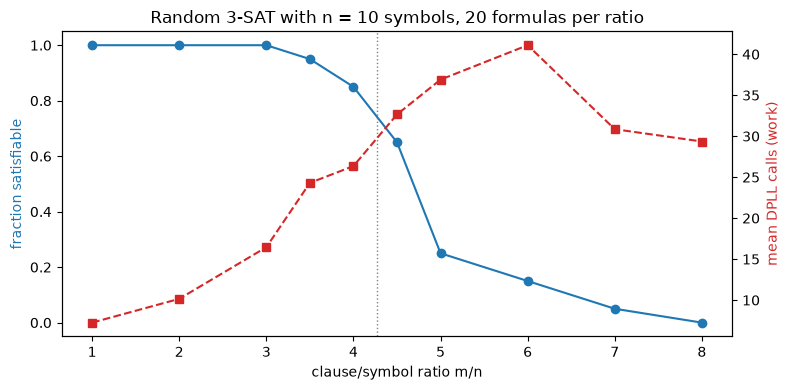

 m/n  P(satisfiable)  mean DPLL calls
 1.0            1.00             7.25
 2.0            1.00            10.15
 3.0            1.00            16.45
 3.5            0.95            24.30
 4.0            0.85            26.35
 4.5            0.65            32.65
 5.0            0.25            36.90
 6.0            0.15            41.10
 7.0            0.05            30.85
 8.0            0.00            29.35


In [29]:
rng = random.Random(0)
n_vars, ratios, trials = 10, [1, 2, 3, 3.5, 4, 4.5, 5, 6, 7, 8], 20
p_sat, mean_calls = [], []
t0 = time.time()
for r in ratios:
    sat, calls = 0, 0
    for _ in range(trials):
        model, st = dpll_satisfiable(random_3cnf(n_vars, int(round(r * n_vars)), rng))
        sat += model is not None
        calls += st["calls"]
    p_sat.append(sat / trials); mean_calls.append(calls / trials)
print(f"Solved {len(ratios) * trials} formulas in {time.time() - t0:.1f} s")

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(ratios, p_sat, "o-", color="tab:blue", label="fraction satisfiable")
ax1.set_xlabel("clause/symbol ratio m/n"); ax1.set_ylabel("fraction satisfiable", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(ratios, mean_calls, "s--", color="tab:red", label="mean DPLL calls")
ax2.set_ylabel("mean DPLL calls (work)", color="tab:red")
ax1.axvline(4.27, color="gray", lw=1, ls=":")
ax1.set_title(f"Random 3-SAT with n = {n_vars} symbols, {trials} formulas per ratio")
fig.tight_layout(); plt.show()
print(pd.DataFrame({"m/n": ratios, "P(satisfiable)": p_sat, "mean DPLL calls": mean_calls}).to_string(index=False))

**What just happened?** At low ratios every formula was satisfiable and DPLL found a model quickly. As the ratio grows the fraction of satisfiable formulas falls and the work (red curve) rises, peaking in the region where formulas are "barely" satisfiable or unsatisfiable; beyond that, contradictions show up quickly and the work drops again. With only n = 10 symbols the transition is blurred and the hardest ratio sits a little to the right of the asymptotic 4.27 (dotted line); with hundreds of symbols the curve becomes a near step at 4.27. The exact numbers are printed in the table above.

### WalkSAT (local search)

**WalkSAT** (Selman, Kautz and Cohen, 1994) starts from a random complete assignment and repeatedly picks a **false clause** and flips one of its symbols: with probability *p* a random one (a "random walk" step that escapes local minima), otherwise the one that minimises the number of false clauses (a greedy step). It is **incomplete**: if it finds a model the formula is satisfiable, but if it gives up we learn nothing, so it cannot prove unsatisfiability (and therefore cannot prove entailment).

In [30]:
def walksat(clauses, p=0.5, max_flips=10_000, seed=0):
    rng = random.Random(seed)
    syms = sorted({l.lstrip("~") for c in clauses for l in c})
    model = {s: rng.random() < 0.5 for s in syms}             # random starting assignment
    for flip in range(max_flips):
        false_clauses = [c for c in clauses if not clause_value(c, model)]
        if not false_clauses:
            return model, flip                                 # every clause true: done
        clause = rng.choice(false_clauses)                     # pick a broken clause
        if rng.random() < p:
            s = rng.choice(sorted(clause)).lstrip("~")         # random walk step
        else:
            def false_after_flip(sym):                         # greedy step: count broken clauses after flipping
                model[sym] = not model[sym]
                n = sum(1 for c in clauses if not clause_value(c, model))
                model[sym] = not model[sym]
                return n
            s = min(sorted(l.lstrip("~") for l in clause), key=false_after_flip)
        model[s] = not model[s]
    return None, max_flips                                     # gave up (NOT a proof of unsatisfiability)

rng = random.Random(21)
found, total = 0, 0
for _ in range(10):
    f = random_3cnf(20, 60, rng)                               # ratio 3: very likely satisfiable
    m_dpll, _ = dpll_satisfiable(f)
    if m_dpll is None:
        continue                                               # only test formulas DPLL says are satisfiable
    total += 1
    m_ws, flips = walksat(f, seed=total)
    if m_ws is not None:
        assert all(clause_value(c, m_ws) for c in f)
        found += 1
print(f"WalkSAT found a model for {found} of {total} satisfiable 20-symbol formulas.")
m_ws, flips = walksat(clauses_of(parse("P & ~P")), max_flips=200)
print("WalkSAT on the unsatisfiable P ∧ ¬P:", m_ws, f"(gave up after {flips} flips, which proves nothing)")

WalkSAT found a model for 10 of 10 satisfiable 20-symbol formulas.
WalkSAT on the unsatisfiable P ∧ ¬P: None (gave up after 200 flips, which proves nothing)


| Algorithm | Complete? | Proves UNSAT? | Time (worst) | Space | Notes |
|---|---|---|---|---|---|
| Truth table (TT-ENTAILS) | yes | yes | O(2ⁿ) | O(n) | always enumerates everything |
| Resolution | yes (refutation) | yes | exponential | exponential | clause sets can explode |
| Forward / backward chaining | yes, **Horn only** | - | **O(size of KB)** | O(size of KB) | linear |
| DPLL / CDCL | yes | yes | O(2ⁿ) | O(n) (plus learnt clauses for CDCL) | fast in practice |
| WalkSAT | **no** | no | - (stops after max flips) | O(n) | often fastest on big satisfiable instances |

> 🎓 **Exam / interview tip:** **2-SAT** (every clause has at most 2 literals) is solvable in **linear time** via strongly connected components of the implication graph, and **Horn-SAT** is linear via unit propagation. **3-SAT** is NP-complete. Questions like "Why is Horn-SAT easy?" expect: unit propagation (forward chaining) never needs to guess.

## 9. The Wumpus world: inferring safe squares

> **In plain English:** a robot explorer in a dark cave uses logic on breezes and smells to work out which squares are safe to step on.

**The game** (AIMA §7.2). A 4×4 cave. The agent starts in square [1,1] (column 1, row 1). Some squares contain a bottomless **pit**; one contains the **wumpus**, a beast that eats anyone who enters; one contains **gold**. The agent cannot see, but it receives **percepts**:
- a **breeze** in squares *adjacent* (up/down/left/right) to a pit,
- a **stench** in squares adjacent to the wumpus,
- a **glitter** in the square with the gold.

Our cave is the classic one from AIMA Fig. 7.2:
```
row 4 │      │      │      │  P   │
row 3 │  W   │ Gold │  P   │      │
row 2 │      │      │      │      │
row 1 │Start │      │  P   │      │
        col 1  col 2  col 3  col 4
```

**The knowledge base.** Symbols: `Pxy` (pit in [x,y]), `Wxy` (wumpus in [x,y]), `Bxy` (breeze perceived in [x,y]), `Sxy` (stench perceived in [x,y]). Background knowledge:
- [1,1] is safe: ¬P11 ∧ ¬W11.
- For each square the agent has visited we TELL the physics of that square, e.g. **B11 ⇔ (P12 ∨ P21)** and **S11 ⇔ (W12 ∨ W21)**, plus the percepts actually received (B11 or ¬B11, and so on). (A full KB would state the rule for all 16 squares up front; adding it only for visited squares gives the same answers about pits and wumpus and keeps the KB small.)

A square is **provably safe** if KB ⊨ ¬Pxy ∧ ¬Wxy. Because the KB has dozens of symbols we ASK with DPLL (`dpll_entails`), then cross-check the key answers with truth tables.

In [31]:
N = 4
TRUE_PITS, TRUE_WUMPUS, TRUE_GOLD = {(3, 1), (3, 3), (4, 4)}, (1, 3), (2, 3)

def neighbours(x, y):
    return [(a, b) for a, b in [(x - 1, y), (x + 1, y), (x, y - 1), (x, y + 1)] if 1 <= a <= N and 1 <= b <= N]

def percept(square):
    """What the environment tells the agent in a square: (breeze, stench, glitter)."""
    nbrs = neighbours(*square)
    return (any(n in TRUE_PITS for n in nbrs), TRUE_WUMPUS in nbrs, square == TRUE_GOLD)

class WumpusKB:
    def __init__(self):
        self.sentences = [parse("~P11"), parse("~W11")]           # the start square is safe
    def tell_percept(self, square, breeze, stench):
        x, y = square
        self.sentences.append(("iff", f"B{x}{y}", ("or", *[f"P{a}{b}" for a, b in neighbours(x, y)])))  # breeze physics
        self.sentences.append(("iff", f"S{x}{y}", ("or", *[f"W{a}{b}" for a, b in neighbours(x, y)])))  # stench physics
        self.sentences.append(f"B{x}{y}" if breeze else ("not", f"B{x}{y}"))     # the actual percepts
        self.sentences.append(f"S{x}{y}" if stench else ("not", f"S{x}{y}"))
    def sentence(self):
        return conj(*self.sentences)
    def known_symbols(self):
        return symbols(self.sentence())
    def status(self, square):
        """Ask the KB what it can prove about a square."""
        x, y = square
        if f"P{x}{y}" not in self.known_symbols():      # the KB never mentions this square, so it
            return "?"                                  # cannot prove anything about it: skip the SAT calls
        kb = self.sentence()
        if dpll_entails(kb, ("and", ("not", f"P{x}{y}"), ("not", f"W{x}{y}"))): return "OK"
        if dpll_entails(kb, f"P{x}{y}"): return "PIT"
        if dpll_entails(kb, f"W{x}{y}"): return "WUMPUS"
        return "?"

def path_through(start, goal, allowed):
    """BFS route from start to goal that only steps on allowed (known-safe) squares."""
    frontier, came = deque([start]), {start: None}
    while frontier:
        s = frontier.popleft()
        if s == goal:
            break
        for n in neighbours(*s):
            if n not in came and (n in allowed or n == goal):
                came[n] = s; frontier.append(n)
    route, s = [], goal
    while s != start:
        route.append(s); s = came[s]
    return route[::-1]

def run_logical_agent(max_steps=10):
    kb, pos, visited, log = WumpusKB(), (1, 1), [], []
    for step in range(max_steps):
        breeze, stench, glitter = percept(pos)
        visited.append(pos)
        kb.tell_percept(pos, breeze, stench)                                     # TELL
        status = {(x, y): kb.status((x, y)) for x in range(1, N + 1) for y in range(1, N + 1)}   # ASK
        log.append({"step": step, "at": pos, "breeze": breeze, "stench": stench, "glitter": glitter,
                    "proved about unvisited squares": ", ".join(f"{s}={v}" for s, v in sorted(status.items()) if v != "?" and s not in visited)})
        if glitter:
            log[-1]["action"] = "GRAB gold, stop"
            return kb, visited, status, pd.DataFrame(log)
        known_safe = {s for s, v in status.items() if v == "OK"}
        safe_unvisited = sorted((s for s in known_safe if s not in visited),
                                key=lambda s: (len(path_through(pos, s, known_safe)), s[1], s[0]))
        if not safe_unvisited:
            log[-1]["action"] = "no safe move left, stop"
            return kb, visited, status, pd.DataFrame(log)
        target = safe_unvisited[0]                                               # nearest provably safe square
        log[-1]["action"] = f"go to {target} via {path_through(pos, target, known_safe)}"
        pos = target
    return kb, visited, status, pd.DataFrame(log)

t0 = time.time()
wkb, visited, final_status, agent_log = run_logical_agent()
print(f"Agent finished in {time.time() - t0:.2f} s; visited {visited}")
agent_log

Agent finished in 4.03 s; visited [(1, 1), (2, 1), (1, 2), (2, 2), (3, 2), (2, 3)]


,step,at,breeze,stench,glitter,proved about unvisited squares,action
0,0,"(1, 1)",False,False,False,"(1, 2)=OK, (2, 1)=OK","go to (2, 1) via [(2, 1)]"
1,1,"(2, 1)",True,False,False,"(1, 2)=OK","go to (1, 2) via [(1, 1), (1, 2)]"
2,2,"(1, 2)",False,True,False,"(1, 3)=WUMPUS, (2, 2)=OK, (3, 1)=PIT","go to (2, 2) via [(2, 2)]"
3,3,"(2, 2)",False,False,False,"(1, 3)=WUMPUS, (2, 3)=OK, (3, 1)=PIT, (3, 2)=OK","go to (3, 2) via [(3, 2)]"
4,4,"(3, 2)",True,False,False,"(1, 3)=WUMPUS, (2, 3)=OK, (3, 1)=PIT","go to (2, 3) via [(2, 2), (2, 3)]"
5,5,"(2, 3)",True,True,True,"(1, 3)=WUMPUS, (3, 1)=PIT","GRAB gold, stop"


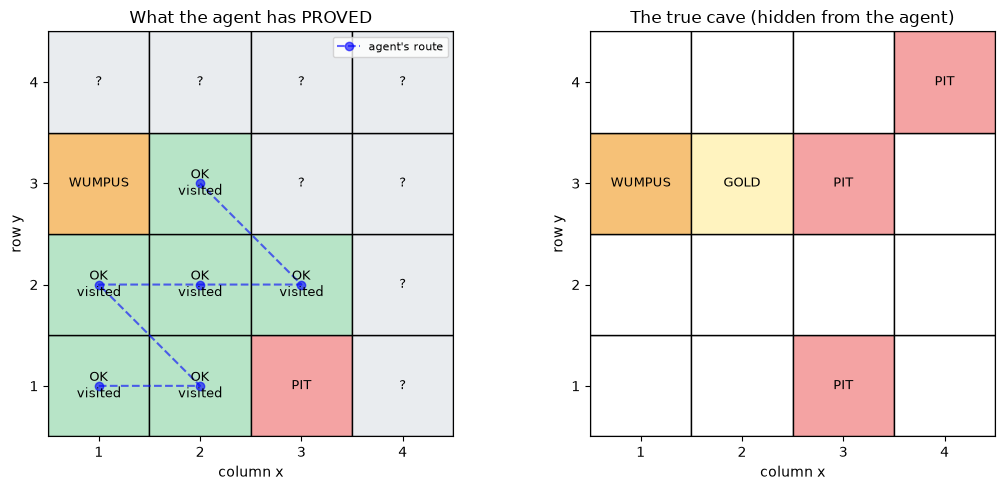

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colours = {"OK": "#b7e4c7", "PIT": "#f4a3a3", "WUMPUS": "#f6c177", "?": "#e9ecef"}
for ax, title in zip(axes, ["What the agent has PROVED", "The true cave (hidden from the agent)"]):
    for x in range(1, N + 1):
        for y in range(1, N + 1):
            if title.startswith("What"):
                st = final_status[(x, y)]
                label = st + ("\nvisited" if (x, y) in visited else "")
                face = colours[st]
            else:
                items = (["PIT"] if (x, y) in TRUE_PITS else []) + (["WUMPUS"] if (x, y) == TRUE_WUMPUS else []) + \
                        (["GOLD"] if (x, y) == TRUE_GOLD else [])
                label = "\n".join(items)
                face = "#f4a3a3" if (x, y) in TRUE_PITS else "#f6c177" if (x, y) == TRUE_WUMPUS else "#fff3bf" if (x, y) == TRUE_GOLD else "white"
            ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=face, edgecolor="black"))
            ax.text(x, y, label, ha="center", va="center", fontsize=9)
    ax.set_xlim(0.5, N + 0.5); ax.set_ylim(0.5, N + 0.5); ax.set_aspect("equal")
    ax.set_xticks(range(1, N + 1)); ax.set_yticks(range(1, N + 1))
    ax.set_xlabel("column x"); ax.set_ylabel("row y"); ax.set_title(title)
xs, ys = zip(*visited)
axes[0].plot(xs, ys, "b--o", alpha=0.6, label="agent's route")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

In [33]:
# Everything the agent proved must be TRUE in the real cave (soundness check).
for (x, y), st in final_status.items():
    if st == "OK":     assert (x, y) not in TRUE_PITS and (x, y) != TRUE_WUMPUS
    if st == "PIT":    assert (x, y) in TRUE_PITS
    if st == "WUMPUS": assert (x, y) == TRUE_WUMPUS

# Cross-check the famous AIMA inferences with truth-table model checking on the KB after
# visiting [1,1], [2,1] and [1,2] (18 symbols -> 2^18 = 262,144 models per question).
kb3 = WumpusKB()
for sq in [(1, 1), (2, 1), (1, 2)]:
    kb3.tell_percept(sq, *percept(sq)[:2])
t0 = time.time()
rows = []
for text in ["~P22 & ~W22", "P31", "W13", "P22"]:
    tt, n = tt_entails(kb3.sentence(), parse(text))
    dp = dpll_entails(kb3.sentence(), parse(text))
    assert tt == dp
    rows.append({"query": show(parse(text)), "TT-ENTAILS": tt, "DPLL": dp, "models checked": n})
print(f"Truth-table cross-check took {time.time() - t0:.1f} s")
pd.DataFrame(rows)

Truth-table cross-check took 20.4 s


,query,TT-ENTAILS,DPLL,models checked
0,¬P22 ∧ ¬W22,True,True,262144
1,P31,True,True,262144
2,W13,True,True,262144
3,P22,False,False,228728


**What just happened?** The agent followed the reasoning of AIMA §7.3 exactly:
1. In [1,1] it felt nothing, so [1,2] and [2,1] are safe. It went to [2,1].
2. In [2,1] it felt a **breeze**: a pit is in [2,2] or [3,1], but it cannot tell which, so nothing new is provably safe. It went back through [1,1] to [1,2].
3. In [1,2] it smelt a **stench** but felt **no breeze**. No breeze means no pit in [2,2] (or [1,3]); combined with the breeze in [2,1] this proves **a pit in [3,1]**. No stench back in [2,1] rules out a wumpus in [2,2] and [3,1], so the stench in [1,2] proves **the wumpus is in [1,3]**. Therefore **[2,2] is safe**.
4. In [2,2] it felt nothing, making [2,3] and [3,2] safe. It tried [3,2] first (our tie-break prefers lower rows) and felt a breeze there, already explained by the known pit in [3,1] (and in fact by the unknown pit in [3,3]), so nothing new about [3,3] or [4,2] could be proved.
5. It walked back through [2,2] to [2,3], saw the **glitter** and grabbed the gold.

The truth-table check confirms the key conclusions by brute force over all 2¹⁸ models, and every "OK/PIT/WUMPUS" label agrees with the hidden map.

> ⚠️ **Common mistake:** "not provably safe" is not "dangerous". After step 2 the agent did not know whether [2,2] had a pit; a logical agent only acts on what is *entailed*. Real agents also need probability (how likely is a pit?), which is where Bayesian reasoning comes in.

**Complexity.** Each ASK is a SAT call: exponential worst case, but DPLL with unit propagation solves these small KBs in milliseconds.

## 10. First-order logic (FOL)

> **In plain English:** first-order logic talks about things and their relationships, and can say 'for every...' and 'there is some...'.

Propositional logic needs a separate symbol for every fact: `B11`, `B12`, … and a separate rule for every square. It cannot say "**every** square adjacent to a pit is breezy" once. **First-order logic** (predicate logic) can, because it talks about **objects** and their **relations**.

**Syntax.**

| Element | What it denotes | Examples |
|---|---|---|
| **Constant symbol** | a specific object | `John`, `M1`, `America` |
| **Variable** | an unspecified object | `x`, `y`, `z` (lowercase in this notebook) |
| **Function symbol** | maps objects to an object | `Mother(John)`, `LeftLeg(x)` |
| **Term** | a constant, variable, or function applied to terms | `Mother(Mother(x))` |
| **Predicate symbol** | a relation that is true or false | `Brother(Richard, John)`, `King(x)` |
| **Atomic sentence** | predicate applied to terms | `Owns(Nono, M1)` |
| **Connectives** | as in propositional logic | ¬ ∧ ∨ ⇒ ⇔ |
| **Quantifiers** | **∀** "for all", **∃** "there exists" | ∀x King(x) ⇒ Person(x) |
| **Equality** | two terms denote the same object | Father(John) = Henry |

**Semantics.** A **model** of FOL has a **domain** (a non-empty set of objects) and an **interpretation** that maps each constant to an object, each predicate to a set of tuples and each function to a mapping. Then:
- ∀x P(x) is true iff P(x) is true for **every** object in the domain.
- ∃x P(x) is true iff P(x) is true for **at least one** object.
- **Duality:** ∀x ¬P(x) ≡ ¬∃x P(x), and ∃x ¬P(x) ≡ ¬∀x P(x) (De Morgan for quantifiers).
- **Order matters** for mixed quantifiers: ∀x ∃y Loves(x, y) ("everybody loves somebody") is weaker than ∃y ∀x Loves(x, y) ("there is someone whom everybody loves").

Because a finite model can be checked directly, we can *evaluate* FOL sentences in Python, with `all()` for ∀ and `any()` for ∃.

In [34]:
# A small finite model: a domain of objects and the extension (set of tuples) of each predicate.
domain = ["Ali", "Sara", "Omar", "Rex"]
Student = {"Ali", "Sara", "Omar"}
Smart   = {"Ali", "Sara", "Omar"}
Lazy    = {"Rex"}                                     # Rex is a (lazy) dog
Loves   = {("Ali", "Sara"), ("Sara", "Omar"), ("Omar", "Ali"), ("Rex", "Ali")}

def implies(a, b):
    return (not a) or b

forall = lambda pred: all(pred(x) for x in domain)    # ∀x pred(x)
exists = lambda pred: any(pred(x) for x in domain)    # ∃x pred(x)

checks = {
    "∀x Student(x) ⇒ Smart(x)       (correct: all students are smart)":   forall(lambda x: implies(x in Student, x in Smart)),
    "∀x Student(x) ∧ Smart(x)       (WRONG: everything is a smart student)": forall(lambda x: x in Student and x in Smart),
    "∃x Student(x) ∧ Lazy(x)        (correct: some student is lazy)":    exists(lambda x: x in Student and x in Lazy),
    "∃x Student(x) ⇒ Lazy(x)        (WRONG: true because of Rex!)":      exists(lambda x: implies(x in Student, x in Lazy)),
    "∀x ∃y Loves(x, y)              (everybody loves somebody)":          forall(lambda x: exists(lambda y: (x, y) in Loves)),
    "∃y ∀x Loves(x, y)              (somebody is loved by everybody)":    exists(lambda y: forall(lambda x: (x, y) in Loves)),
    "¬∃x Student(x) ∧ Lazy(x)  vs  ∀x Student(x) ⇒ ¬Lazy(x)  (duality)":
        (not exists(lambda x: x in Student and x in Lazy)) == forall(lambda x: implies(x in Student, x not in Lazy)),
}
for sentence, value in checks.items():
    print(f"{str(value):5}  {sentence}")

True   ∀x Student(x) ⇒ Smart(x)       (correct: all students are smart)
False  ∀x Student(x) ∧ Smart(x)       (WRONG: everything is a smart student)
False  ∃x Student(x) ∧ Lazy(x)        (correct: some student is lazy)
True   ∃x Student(x) ⇒ Lazy(x)        (WRONG: true because of Rex!)
True   ∀x ∃y Loves(x, y)              (everybody loves somebody)
False  ∃y ∀x Loves(x, y)              (somebody is loved by everybody)
True   ¬∃x Student(x) ∧ Lazy(x)  vs  ∀x Student(x) ⇒ ¬Lazy(x)  (duality)


**What just happened?** The same English sentence gave different truth values depending on the connective we paired with the quantifier. "All students are smart" is true, but the ∧ version is false because Rex (a dog) is not a student. "Some student is lazy" is false, yet the ⇒ version is *true*: for x = Rex, "Student(Rex) ⇒ Lazy(Rex)" has a false premise, so it holds trivially. The two mixed-quantifier sentences also differ: everybody loves somebody, but nobody is loved by everybody.

## 11. Translating English into FOL

> **In plain English:** turning English into logic has traps: 'all' almost always pairs with IF-THEN, and 'some' with AND.

| # | English | Correct FOL | Common mistake | Why the mistake is wrong |
|---|---|---|---|---|
| 1 | All students are smart. | ∀x Student(x) ⇒ Smart(x) | ∀x Student(x) ∧ Smart(x) | says *everything* is a smart student |
| 2 | Some student is smart. | ∃x Student(x) ∧ Smart(x) | ∃x Student(x) ⇒ Smart(x) | true as soon as one non-student exists |
| 3 | No student is lazy. | ∀x Student(x) ⇒ ¬Lazy(x)  (≡ ¬∃x Student(x) ∧ Lazy(x)) | ∀x ¬Student(x) ∧ ¬Lazy(x) | says nothing is a student |
| 4 | Not all students are lazy. | ¬∀x (Student(x) ⇒ Lazy(x))  (≡ ∃x Student(x) ∧ ¬Lazy(x)) | ∀x Student(x) ⇒ ¬Lazy(x) | that is "no student is lazy" (too strong) |
| 5 | Everybody loves somebody. | ∀x ∃y Loves(x, y) | ∃y ∀x Loves(x, y) | quantifier order swapped: one person loved by all |
| 6 | There is someone whom everybody loves. | ∃y ∀x Loves(x, y) | ∀x ∃y Loves(x, y) | weaker: each may love a different person |
| 7 | Brothers are siblings. | ∀x ∀y Brother(x, y) ⇒ Sibling(x, y) | ∀x ∀y Brother(x, y) ⇔ Sibling(x, y) | sisters are siblings too: ⇔ is too strong |
| 8 | Everyone's mother is older than them. | ∀x Person(x) ⇒ Older(Mother(x), x) | ∀x ∀y Mother(y) ∧ Older(y, x) | Mother is a *function* (one per person), not a property of y |
| 9 | Exactly one student failed AI. | ∃x Student(x) ∧ Failed(x, AI) ∧ ∀y (Student(y) ∧ Failed(y, AI) ⇒ y = x) | ∃x Student(x) ∧ Failed(x, AI) | that is "at least one" |
| 10 | It is a crime for an American to sell weapons to hostile nations. | ∀x ∀y ∀z American(x) ∧ Weapon(y) ∧ Sells(x, y, z) ∧ Hostile(z) ⇒ Criminal(x) | ∀x ∃y ∃z American(x) ∧ Weapon(y) ∧ Sells(x, y, z) ∧ Hostile(z) ⇒ Criminal(x) | ∃ inside a rule body: the quantifier scope changes the meaning |

> ⚠️ **Common mistake (the rule of thumb):** **∀ goes with ⇒** and **∃ goes with ∧**. "∀ with ∧" is almost always too strong; "∃ with ⇒" is almost always too weak.

> 🎓 **Exam / interview tip:** when asked to translate, first identify the *quantifier* ("all, every, any" → ∀; "some, a, there is" → ∃), then the *restriction* (students), then the *claim* (smart). Write ∀x Restriction(x) ⇒ Claim(x) or ∃x Restriction(x) ∧ Claim(x).

## 12. Unification

> **In plain English:** unification is pattern matching with blanks: find values for the blanks that make two expressions identical.

**Intuition.** Inference in FOL needs to *match* a rule like King(x) ∧ Greedy(x) ⇒ Evil(x) with a fact like King(John). Matching means finding values for the variables that make two expressions identical.

**Definitions.**
- A **substitution** θ is a set of bindings {variable/term}, e.g. θ = {x/John}. SUBST(θ, p) applies it: SUBST({x/John}, King(x)) = King(John).
- **UNIFY(p, q) = θ** where SUBST(θ, p) = SUBST(θ, q). θ is a **unifier**. Among all unifiers there is a **most general unifier (MGU)**, unique up to renaming of variables, which commits to as little as possible: for Knows(John, x) and Knows(y, z) the MGU is {y/John, x/z}, not {y/John, x/John, z/John}.
- The **occurs check**: a variable cannot be bound to a term that contains it. x and F(x) do not unify, because x = F(x) = F(F(x)) = … would be an infinite term.
- **Standardizing apart**: rename the variables of each rule before use, so that the x in one sentence is not confused with an unrelated x in another.

Worked examples (AIMA §9.2.2):

| p | q | UNIFY(p, q) |
|---|---|---|
| Knows(John, x) | Knows(John, Jane) | {x/Jane} |
| Knows(John, x) | Knows(y, Bill) | {x/Bill, y/John} |
| Knows(John, x) | Knows(y, Mother(y)) | {y/John, x/Mother(John)} |
| Knows(John, x) | Knows(x, Elizabeth) | fail (x cannot be both John and Elizabeth) |
| Knows(John, x) | Knows(x17, Elizabeth) | {x/Elizabeth, x17/John} (after standardizing apart) |

In the code, **variables are lowercase** (`x`, `y_3`) and constants, functions and predicates are Capitalized. A compound term `Knows(John, x)` is the tuple `('Knows', 'John', 'x')`.

In [35]:
def is_var(t):
    return isinstance(t, str) and t[:1].islower()

def parse_term(text):
    """'Knows(John, Mother(x))' -> ('Knows', 'John', ('Mother', 'x'))."""
    text = text.strip()
    m = re.match(r"^([A-Za-z_][A-Za-z0-9_]*)\s*(\((.*)\))?$", text)
    if not m:
        raise SyntaxError(text)
    name, inner = m.group(1), m.group(3)
    if inner is None:
        return name                                   # a constant or a variable
    parts, depth, cur = [], 0, ""
    for ch in inner:                                  # split on commas that are not nested
        if ch == "," and depth == 0:
            parts.append(cur); cur = ""; continue
        depth += (ch == "(") - (ch == ")")
        cur += ch
    parts.append(cur)
    return (name, *[parse_term(p) for p in parts])

def fshow(t):
    return t if isinstance(t, str) else f"{t[0]}({', '.join(fshow(a) for a in t[1:])})"

def substitute(theta, t):
    """SUBST(theta, t), following chains of bindings such as x/y, y/John."""
    if is_var(t):
        return substitute(theta, theta[t]) if t in theta else t
    if isinstance(t, tuple):
        return (t[0], *[substitute(theta, a) for a in t[1:]])
    return t

def occurs(var, t, theta):
    """Occurs check: does var appear inside t (after applying theta)?"""
    if var == t:
        return True
    if is_var(t) and t in theta:
        return occurs(var, theta[t], theta)
    if isinstance(t, tuple):
        return any(occurs(var, a, theta) for a in t[1:])
    return False

def show_theta(theta):
    if theta is None:
        return "failure"
    return "{" + ", ".join(f"{k}/{fshow(substitute(theta, v))}" for k, v in sorted(theta.items())) + "}"

def unify(x, y, theta=None, trace=None):
    """UNIFY (AIMA Fig. 9.1) with the occurs check. Returns a substitution dict or None."""
    if theta is None:
        theta = {}
    if trace is not None: trace.append(f"unify {fshow(x)} with {fshow(y)}   θ = {show_theta(theta)}")
    if x == y:                                              # identical: nothing to do
        return theta
    if is_var(x):
        return unify_var(x, y, theta, trace)
    if is_var(y):
        return unify_var(y, x, theta, trace)
    if isinstance(x, tuple) and isinstance(y, tuple):       # compound terms: same functor and arity?
        if x[0] != y[0] or len(x) != len(y):
            if trace is not None: trace.append(f"   FAIL: {x[0]}/{len(x) - 1} cannot match {y[0]}/{len(y) - 1}")
            return None
        for a, b in zip(x[1:], y[1:]):                      # unify the arguments left to right
            theta = unify(a, b, theta, trace)
            if theta is None:
                return None
        return theta
    if trace is not None: trace.append(f"   FAIL: different constants {fshow(x)} and {fshow(y)}")
    return None

def unify_var(var, t, theta, trace):
    if var in theta:                                        # var already bound: unify its value
        return unify(theta[var], t, theta, trace)
    if is_var(t) and t in theta:
        return unify(var, theta[t], theta, trace)
    if occurs(var, t, theta):                               # x = F(x) would be an infinite term
        if trace is not None: trace.append(f"   FAIL (occurs check): {var} occurs inside {fshow(substitute(theta, t))}")
        return None
    return {**theta, var: t}                                # bind var to t

def variables(t):
    if is_var(t): return {t}
    if isinstance(t, tuple): return set().union(*(variables(a) for a in t[1:]))
    return set()

unify_tests = [
    ("Knows(John, x)", "Knows(John, Jane)", "{x/Jane}"),
    ("Knows(John, x)", "Knows(y, Bill)", "{x/Bill, y/John}"),
    ("Knows(John, x)", "Knows(y, Mother(y))", "{x/Mother(John), y/John}"),
    ("Knows(John, x)", "Knows(x, Elizabeth)", "failure"),
    ("Knows(John, x)", "Knows(x17, Elizabeth)", "{x/Elizabeth, x17/John}"),
    ("Knows(John, x)", "Knows(y, z)", "{x/z, y/John}"),
    ("P(x)", "P(F(x))", "failure"),
    ("P(x, F(x))", "P(G(y), y)", "failure"),
    ("Older(Mother(x), x)", "Older(Mother(Ali), y)", "{x/Ali, y/Ali}"),
    ("Knows(John, x)", "Likes(John, x)", "failure"),
]
rows = []
for p, q, expected in unify_tests:
    result = show_theta(unify(parse_term(p), parse_term(q)))
    assert result == expected, (p, q, result)
    rows.append({"p": p, "q": q, "UNIFY(p, q)": result})
pd.DataFrame(rows)

,p,q,"UNIFY(p, q)"
0,"Knows(John, x)","Knows(John, Jane)",{x/Jane}
1,"Knows(John, x)","Knows(y, Bill)","{x/Bill, y/John}"
2,"Knows(John, x)","Knows(y, Mother(y))","{x/Mother(John), y/John}"
3,"Knows(John, x)","Knows(x, Elizabeth)",failure
4,"Knows(John, x)","Knows(x17, Elizabeth)","{x/Elizabeth, x17/John}"
5,"Knows(John, x)","Knows(y, z)","{x/z, y/John}"
6,P(x),P(F(x)),failure
7,"P(x, F(x))","P(G(y), y)",failure
8,"Older(Mother(x), x)","Older(Mother(Ali), y)","{x/Ali, y/Ali}"
9,"Knows(John, x)","Likes(John, x)",failure


In [36]:
for p, q in [("Knows(John, x)", "Knows(y, Mother(y))"), ("P(x, F(x))", "P(G(y), y)")]:
    steps = []
    unify(parse_term(p), parse_term(q), trace=steps)
    print(f"--- {p}  vs  {q}"); print("\n".join(steps)); print()

--- Knows(John, x)  vs  Knows(y, Mother(y))
unify Knows(John, x) with Knows(y, Mother(y))   θ = {}
unify John with y   θ = {}
unify x with Mother(y)   θ = {y/John}

--- P(x, F(x))  vs  P(G(y), y)
unify P(x, F(x)) with P(G(y), y)   θ = {}
unify x with G(y)   θ = {}
unify F(x) with y   θ = {x/G(y)}
   FAIL (occurs check): y occurs inside F(G(y))



**What just happened?** Unification walked both expressions in parallel, binding variables as it went. In the second trace it bound x to G(y) and then had to unify F(x), which is now F(G(y)), with y; since y occurs inside F(G(y)), the **occurs check** rejected it. Without the check we would have built an infinite term and could prove false things.

**Complexity.** With the occurs check the simple recursive algorithm is **quadratic** in the size of the expressions; linear-time algorithms exist (Paterson & Wegman, 1978). For speed, **Prolog omits the occurs check by default**, which is technically unsound in rare cases (`X = f(X)` succeeds in most Prologs; ISO Prolog offers `unify_with_occurs_check/2`).

## 13. Generalized modus ponens and forward chaining in FOL

> **In plain English:** with pattern matching we can apply general rules ('anyone who...') to specific facts, repeating until we reach the answer.

**Generalized Modus Ponens (GMP).** For atomic sentences pᵢ, pᵢ' and q, if there is a substitution θ with SUBST(θ, pᵢ') = SUBST(θ, pᵢ) for every i:

```
   p1',  p2',  ...,  pn',      (p1 ∧ p2 ∧ ... ∧ pn ⇒ q)
  ─────────────────────────────────────────────────────
                   SUBST(θ, q)
```
Example: from King(John), Greedy(y) ("everyone is greedy") and King(x) ∧ Greedy(x) ⇒ Evil(x), with θ = {x/John, y/John}, infer Evil(John). GMP is a **lifted** version of modus ponens: it works directly with variables instead of first creating every ground instance. It is **sound**, and with forward or backward chaining it is **complete for first-order definite clauses** (rules with exactly one positive literal).

**The "Colonel West" story (AIMA §9.3).**
> The law says that it is a crime for an American to sell weapons to hostile nations. The country Nono, an enemy of America, has some missiles, and all of its missiles were sold to it by Colonel West, who is American. **Prove that West is a criminal.**

| English | First-order definite clause |
|---|---|
| it is a crime for an American to sell weapons to hostile nations | American(x) ∧ Weapon(y) ∧ Sells(x, y, z) ∧ Hostile(z) ⇒ Criminal(x) |
| Nono has some missiles (∃x Owns(Nono, x) ∧ Missile(x)); call one M1 (*Skolem constant*) | Owns(Nono, M1);  Missile(M1) |
| all of its missiles were sold to it by Colonel West | Missile(x) ∧ Owns(Nono, x) ⇒ Sells(West, x, Nono) |
| missiles are weapons | Missile(x) ⇒ Weapon(x) |
| an enemy of America counts as "hostile" | Enemy(x, America) ⇒ Hostile(x) |
| West, who is American | American(West) |
| the country Nono, an enemy of America | Enemy(Nono, America) |

This KB has no function symbols, so it is a **Datalog** program.

In [37]:
def fol_rule(text):
    """'A(x) & B(x) ==> C(x)' -> ([A(x), B(x)], C(x));  a fact has an empty body."""
    if "==>" in text:
        body, head = text.split("==>")
        return ([parse_term(b) for b in body.split("&")], parse_term(head))
    return ([], parse_term(text))

def show_rule(rule):
    body, head = rule
    return (" ∧ ".join(fshow(b) for b in body) + " ⇒ " if body else "") + fshow(head)

rename_counter = itertools.count(1)

def standardize_apart(rule):
    """Give the rule's variables fresh names (x -> x_7) so different uses never clash."""
    body, head = rule
    n = next(rename_counter)
    ren = {v: f"{v}_{n}" for v in set().union(variables(head), *(variables(b) for b in body))}
    return [substitute(ren, b) for b in body], substitute(ren, head)

def match_body(body, facts, theta):
    """Yield every substitution that makes all body atoms match known facts (a join)."""
    if not body:
        yield theta; return
    for f in facts:
        t2 = unify(body[0], f, theta)
        if t2 is not None:
            yield from match_body(body[1:], facts, t2)

def fol_fc_ask(kb_rules, query):
    """FOL-FC-ASK (AIMA Fig. 9.3): returns (answer substitution or None, all facts, log, support)."""
    facts = [h for b, h in kb_rules if not b]
    rules = [r for r in kb_rules if r[0]]
    log, support, iteration = [], {}, 0
    while True:
        iteration += 1
        new = []
        for rule in rules:
            body, head = standardize_apart(rule)
            for theta in match_body(body, facts, {}):          # only facts known at the START of this iteration
                q2 = substitute(theta, head)
                if q2 not in facts and q2 not in new:          # ground facts: "renaming" = equality
                    new.append(q2)
                    support[q2] = [substitute(theta, b) for b in body]
                    pretty = {k.rsplit("_", 1)[0]: fshow(substitute(theta, v)) for k, v in theta.items()}
                    log.append({"iteration": iteration, "rule": show_rule(rule),
                                "θ": "{" + ", ".join(f"{k}/{v}" for k, v in sorted(pretty.items())) + "}",
                                "new fact": fshow(q2)})
        if not new:
            return None, facts, pd.DataFrame(log), support      # fixed point reached
        facts = facts + new
        answer = next((unify(query, f) for f in new if unify(query, f) is not None), None)
        if answer is not None:
            return answer, facts, pd.DataFrame(log), support

west_kb = [fol_rule(r) for r in [
    "American(x) & Weapon(y) & Sells(x, y, z) & Hostile(z) ==> Criminal(x)",
    "Missile(x) & Owns(Nono, x) ==> Sells(West, x, Nono)",
    "Missile(x) ==> Weapon(x)",
    "Enemy(x, America) ==> Hostile(x)",
    "Owns(Nono, M1)", "Missile(M1)", "American(West)", "Enemy(Nono, America)",
]]
answer, west_facts, west_log, west_support = fol_fc_ask(west_kb, parse_term("Criminal(q)"))
print("Answer to Criminal(q):", show_theta(answer))
assert show_theta(answer) == "{q/West}"
west_log

Answer to Criminal(q): {q/West}


,iteration,rule,θ,new fact
0,1,"Missile(x) ∧ Owns(Nono, x) ⇒ Sells(West, x, Nono)",{x/M1},"Sells(West, M1, Nono)"
1,1,Missile(x) ⇒ Weapon(x),{x/M1},Weapon(M1)
2,1,"Enemy(x, America) ⇒ Hostile(x)",{x/Nono},Hostile(Nono)
3,2,"American(x) ∧ Weapon(y) ∧ Sells(x, y, z) ∧ Hostile(z) ⇒ Criminal(x)","{x/West, y/M1, z/Nono}",Criminal(West)


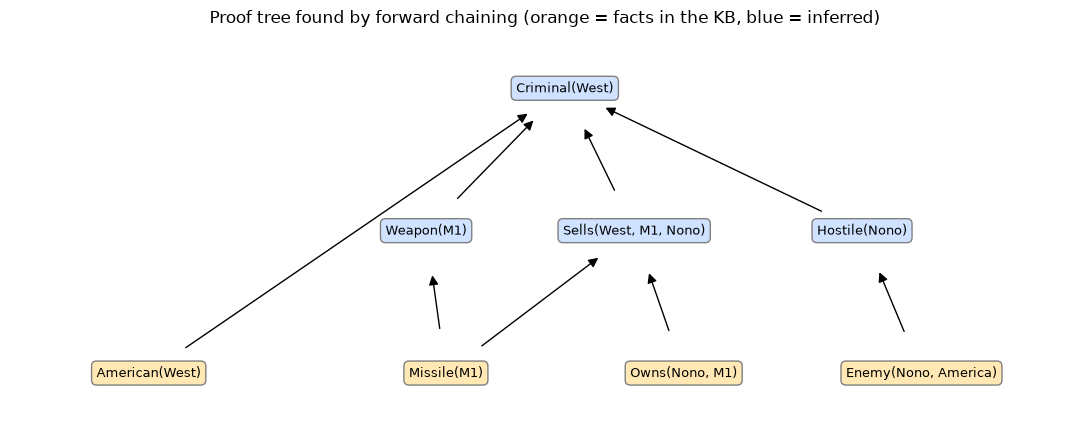

In [38]:
# Draw the proof tree recorded by forward chaining (facts at the bottom, the goal at the top).
tree = nx.DiGraph()
def add_support(fact):
    for premise in west_support.get(fact, []):
        tree.add_edge(fshow(premise), fshow(fact))
        add_support(premise)
goal = parse_term("Criminal(West)")
tree.add_node(fshow(goal)); add_support(goal)
pos_t = {"Criminal(West)": (0, 2),                                         # hand-placed layout, no crossings
         "Weapon(M1)": (-0.7, 1), "Sells(West, M1, Nono)": (0.35, 1), "Hostile(Nono)": (1.5, 1),
         "American(West)": (-2.1, 0), "Missile(M1)": (-0.6, 0), "Owns(Nono, M1)": (0.6, 0), "Enemy(Nono, America)": (1.8, 0)}
assert set(pos_t) == set(tree.nodes)
leaf = [n for n in tree if tree.in_degree(n) == 0]
fig, ax = plt.subplots(figsize=(11, 4.5))
nx.draw_networkx_edges(tree, pos_t, arrowsize=14, node_size=4200, ax=ax)
for n, (x, y) in pos_t.items():
    ax.text(x, y, n, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc="#ffe8b3" if n in leaf else "#cfe2ff", ec="gray"))
ax.set_xlim(-2.8, 2.6); ax.set_ylim(-0.4, 2.4)
ax.set_title("Proof tree found by forward chaining (orange = facts in the KB, blue = inferred)")
ax.axis("off"); plt.tight_layout(); plt.show()

**What just happened?** In iteration 1 three rules fired using only the original facts: Sells(West, M1, Nono), Weapon(M1) and Hostile(Nono). In iteration 2 the crime rule could finally match all four premises with θ = {x/West, y/M1, z/Nono}, adding Criminal(West), which unifies with the query Criminal(q) and gives the answer q = West. Every new fact here is ground (no variables), so "is it new?" is a simple equality test.

**Complexity.** Matching a rule body against the facts is a **conjunctive query (a join)**, which is NP-hard in general (it can encode graph colouring). For Datalog, the number of possible facts is at most p · nᵏ (p predicates of arity ≤ k, n constants), so forward chaining reaches a **fixed point in polynomial time** for a fixed KB. Real engines use indexing, the **Rete** algorithm and **semi-naive evaluation** (only match rules against facts that were new in the previous iteration).

**Checking against truth-table entailment.** Since this KB has no functions, it is equivalent to its **propositionalization**: replace every rule by all its ground instances over the constants {West, M1, Nono, America}. Then the propositional algorithms apply. We check the FOL answer three ways.

In [39]:
constants = ["West", "M1", "Nono", "America"]

def ground_atom(atom):
    return "_".join([atom[0], *atom[1:]])                  # Sells(West, M1, Nono) -> Sells_West_M1_Nono

def propositionalize(kb_rules):
    """Every ground instance of every rule, as propositional Horn rules."""
    out = []
    for body, head in kb_rules:
        vs = sorted(set().union(variables(head), *(variables(b) for b in body)))
        for values in itertools.product(constants, repeat=len(vs)):
            theta = dict(zip(vs, values))
            out.append(([ground_atom(substitute(theta, b)) for b in body], ground_atom(substitute(theta, head))))
    return out

ground_kb = propositionalize(west_kb)
ground_symbols = {s for body, head in ground_kb for s in body + [head]}
print(f"Ground KB: {len(ground_kb)} rules over {len(ground_symbols)} propositional symbols")

# (1) Propositional forward chaining and (2) DPLL on the FULL ground KB.
for q, expected in [("Criminal_West", True), ("Criminal_Nono", False), ("Hostile_America", False)]:
    assert pl_fc_entails(ground_kb, q) == expected
    assert dpll_entails(horn_to_sentence(ground_kb), q) == expected
print("Ground forward chaining and DPLL agree with FOL forward chaining.")

# (3) Truth tables need a small KB, so keep only the ground instances FOL-FC actually used.
used = {}
for fact, premises in west_support.items():
    used[ground_atom(fact)] = [ground_atom(p) for p in premises]
relevant = [([], ground_atom(h)) for b, h in west_kb if not b] + [(b, h) for h, b in used.items()]
relevant_sentence = horn_to_sentence(relevant)
ok, n_models = tt_entails(relevant_sentence, "Criminal_West")
print(f"TT-ENTAILS on the {len(symbols(relevant_sentence))}-symbol relevant instance: Criminal_West entailed = {ok} ({n_models} models checked)")
assert ok and not tt_entails(relevant_sentence, "Criminal_Nono")[0]

Ground KB: 80 rules over 92 propositional symbols


Ground forward chaining and DPLL agree with FOL forward chaining.
TT-ENTAILS on the 8-symbol relevant instance: Criminal_West entailed = True (256 models checked)


> ⚠️ **Common mistake:** propositionalization explodes. The crime rule alone has 3 variables, so it gets 4³ = 64 ground instances; with function symbols (Mother(Mother(…))) there are **infinitely many** ground terms. Lifted inference (unification) avoids generating instances that can never be used.

## 14. Backward chaining à la Prolog

> **In plain English:** start from the question and ask 'what would I need to know to prove this?', the way the Prolog language runs.

**Backward chaining** in FOL works from the goal: to prove Criminal(q), find a rule whose head **unifies** with it, then prove each premise in turn, left to right, carrying the substitution along. It is a **depth-first** search over an AND-OR tree, and it is exactly how **Prolog** executes programs.

The West KB in Prolog syntax (Prolog writes variables in Uppercase, constants in lowercase, and `head :- body.`):
```prolog
criminal(X) :- american(X), weapon(Y), sells(X, Y, Z), hostile(Z).
sells(west, X, nono) :- missile(X), owns(nono, X).
weapon(X)   :- missile(X).
hostile(X)  :- enemy(X, america).
owns(nono, m1).   missile(m1).   american(west).   enemy(nono, america).

?- criminal(Who).
Who = west.
```

Our version is a Python **generator**: it `yield`s one substitution per proof, so asking for more answers is just asking the generator for the next value (like typing `;` in Prolog).

In [40]:
def fol_bc_ask(kb_rules, goals, theta, depth=0, trace=None, max_depth=25):
    """FOL-BC-ASK: yield every substitution that proves all goals (depth-first, left-to-right)."""
    if not goals:
        yield theta                                         # nothing left to prove: success
        return
    if depth > max_depth:                                   # guard against infinite recursion
        return
    goal = substitute(theta, goals[0])                      # apply what we know so far
    pad = "  " * depth
    if trace is not None: trace.append(f"{pad}goal  {fshow(goal)}")
    for rule in kb_rules:                                   # try rules in program order (as Prolog does)
        body, head = standardize_apart(rule)
        t2 = unify(head, goal, dict(theta))
        if t2 is None:
            continue
        if trace is not None and body:
            trace.append(f"{pad}  use rule  {show_rule((body, head))}")
        for t3 in fol_bc_ask(kb_rules, body, t2, depth + 1, trace, max_depth):    # prove the body (AND)
            if trace is not None: trace.append(f"{pad}  ✓ {fshow(substitute(t3, goal))}")
            yield from fol_bc_ask(kb_rules, goals[1:], t3, depth, trace, max_depth)  # then the rest

bc_west_trace = []
first = next(fol_bc_ask(west_kb, [parse_term("Criminal(q)")], {}, trace=bc_west_trace))
print("\n".join(bc_west_trace))
print("\nAnswer: q =", fshow(substitute(first, "q")))
assert substitute(first, "q") == "West"

goal  Criminal(q)
  use rule  American(x_9) ∧ Weapon(y_9) ∧ Sells(x_9, y_9, z_9) ∧ Hostile(z_9) ⇒ Criminal(x_9)
  goal  American(q)
    ✓ American(West)
  goal  Weapon(y_9)
    use rule  Missile(x_19) ⇒ Weapon(x_19)
    goal  Missile(y_9)
      ✓ Missile(M1)
    ✓ Weapon(M1)
  goal  Sells(West, M1, z_9)
    use rule  Missile(x_27) ∧ Owns(Nono, x_27) ⇒ Sells(West, x_27, Nono)
    goal  Missile(M1)
      ✓ Missile(M1)
    goal  Owns(Nono, M1)
      ✓ Owns(Nono, M1)
    ✓ Sells(West, M1, Nono)
  goal  Hostile(Nono)
    use rule  Enemy(x_42, America) ⇒ Hostile(x_42)
    goal  Enemy(Nono, America)
      ✓ Enemy(Nono, America)
    ✓ Hostile(Nono)
  ✓ Criminal(West)

Answer: q = West


The trace shows *standardized-apart* variables such as `y_7`: the rule's `y` was renamed so it cannot clash with any other `y`. Once `Weapon(y_7)` was proved via `Missile(M1)`, the binding y_7/M1 flowed into the next goal, which became `Sells(West, M1, z_7)`.

A family database shows **multiple answers** and **recursion**:

In [41]:
family_kb = [fol_rule(r) for r in [
    "Parent(Tom, Bob)", "Parent(Tom, Liz)", "Parent(Bob, Ann)", "Parent(Bob, Pat)", "Parent(Pat, Jim)",
    "Parent(x, y) ==> Ancestor(x, y)",                       # base case
    "Parent(x, y) & Ancestor(y, z) ==> Ancestor(x, z)",       # recursive case (right-recursive: safe)
]]
bc_answers = sorted(fshow(substitute(t, "who"))
                    for t in fol_bc_ask(family_kb, [parse_term("Ancestor(Tom, who)")], {}))
print("Backward chaining, Ancestor(Tom, who):", bc_answers)

# Check: forward chaining to the fixed point must derive exactly the same Ancestor(Tom, _) facts.
_, all_facts, _, _ = fol_fc_ask(family_kb, parse_term("Nothing(x)"))      # a query that never matches: run to fixed point
fc_answers = sorted(fshow(f[2]) for f in all_facts if f[0] == "Ancestor" and f[1] == "Tom")
print("Forward chaining (fixed point) Ancestor(Tom, _):", fc_answers)
assert bc_answers == fc_answers == ["Ann", "Bob", "Jim", "Liz", "Pat"]

# Left recursion: the SAME logic written in a different order makes depth-first search loop.
looping_kb = family_kb[:5] + [fol_rule("Ancestor(x, y) & Parent(y, z) ==> Ancestor(x, z)"), fol_rule("Parent(x, y) ==> Ancestor(x, y)")]
loop_trace = []
looped = list(fol_bc_ask(looping_kb, [parse_term("Ancestor(Tom, Jim)")], {}, trace=loop_trace, max_depth=12))
deepest = max((len(line) - len(line.lstrip(" "))) // 2 for line in loop_trace if line.lstrip().startswith("goal"))
print("First goals of the left-recursive search:")
print("\n".join(l for l in loop_trace[:6]))
print(f"... {len(loop_trace)} trace lines; recursion went {deepest} levels deep and only stopped at our depth limit (12).")
print(f"Proofs found within the limit: {len(looped)}")

Backward chaining, Ancestor(Tom, who): ['Ann', 'Bob', 'Jim', 'Liz', 'Pat']
Forward chaining (fixed point) Ancestor(Tom, _): ['Ann', 'Bob', 'Jim', 'Liz', 'Pat']


First goals of the left-recursive search:
goal  Ancestor(Tom, Jim)
  use rule  Ancestor(x_190, y_190) ∧ Parent(y_190, z_190) ⇒ Ancestor(x_190, z_190)
  goal  Ancestor(Tom, y_190)
    use rule  Ancestor(x_196, y_196) ∧ Parent(y_196, z_196) ⇒ Ancestor(x_196, z_196)
    goal  Ancestor(Tom, y_196)
      use rule  Ancestor(x_202, y_202) ∧ Parent(y_202, z_202) ⇒ Ancestor(x_202, z_202)
... 206 trace lines; recursion went 12 levels deep and only stopped at our depth limit (12).
Proofs found within the limit: 1


**What just happened?** The generator found all five descendants of Tom, matching forward chaining exactly. When the recursive rule was written **left-recursively** and placed first (`Ancestor(x, y) ∧ Parent(y, z) ⇒ Ancestor(x, z)`), the very first thing backward chaining does is call Ancestor again with a fresh variable, and again, and again: the printed goals show the descent `Ancestor(Tom, y_…)` → `Ancestor(Tom, y_…)` → …. Logically the KB is the same; only the *search order* changed. Real Prolog would run out of stack; our `max_depth` guard cut it off.

| Property | Backward chaining / Prolog |
|---|---|
| Search | depth-first, left-to-right, rules in program order |
| Complete? | **no** (infinite loops on left recursion or cycles); **tabling** (as in XSB and SWI-Prolog) fixes this for Datalog |
| Space | linear in the depth of the proof |
| Repeated work | yes, unless results are memoized (tabling) |
| Extras in Prolog | **negation as failure** (`\+ P` succeeds if P cannot be proved, i.e. the **closed-world assumption**), the cut `!`, built-in arithmetic, and no occurs check by default |

## 15. Resolution in FOL, briefly

> **In plain English:** the proof-by-contradiction method also works for first-order logic, after a few clean-up steps.

Forward and backward chaining are only complete for definite clauses. **Resolution** (Robinson, 1965) works for **all** of first-order logic.

**Step 1: convert to CNF.** As in propositional logic, plus two quantifier steps:
1. Eliminate ⇔ and ⇒; move ¬ inwards (¬∀x p ≡ ∃x ¬p, ¬∃x p ≡ ∀x ¬p).
2. **Standardize variables** (each quantifier gets its own variable name).
3. **Skolemize:** remove ∃ by introducing a new function of the enclosing ∀ variables. ∃x Owns(Nono, x) becomes Owns(Nono, M1) (a **Skolem constant**), but ∀x ∃y Loves(x, y) becomes ∀x Loves(x, F(x)) (a **Skolem function**: the loved one depends on x).
4. Drop the ∀ (all remaining variables are universal) and distribute ∨ over ∧.

**Step 2: binary resolution with unification.** Two clauses with literals ℓ and ¬m where UNIFY(ℓ, m) = θ resolve to SUBST(θ, the remaining literals). Together with **factoring** (merging literals that unify) this is **refutation-complete**: if KB ⊨ α, resolution will eventually derive □ from KB ∧ ¬α.

**Step 3: a strategy.** Below we use the **set-of-support / linear input** strategy: always resolve the latest clause (starting from the negated goal) with a KB clause. For Horn clauses this strategy is complete, and it is literally what Prolog does (called **SLD resolution**).

In [42]:
def clause_text(lits):
    """Literals are ('+', atom) or ('-', atom); print them as a disjunction."""
    return "□" if not lits else " ∨ ".join(("¬" if s == "-" else "") + fshow(a) for s, a in lits)

def rule_to_clause(rule):
    body, head = rule
    return [("+", head)] + [("-", b) for b in body]          # B1 ∧ B2 ⇒ H  ==  H ∨ ¬B1 ∨ ¬B2

def linear_resolution(kb_rules, goal_atom, max_depth=15):
    """Refute ¬goal with linear input resolution; yields (answer θ, list of proof steps)."""
    def search(clause, theta, steps, depth):
        if not clause:                                        # empty clause: contradiction found
            yield theta, steps; return
        if depth > max_depth:
            return
        sign, atom = clause[0]                                # resolve on the first (negative) literal
        atom = substitute(theta, atom)
        for rule in kb_rules:
            body, head = standardize_apart(rule)
            t2 = unify(head, atom, dict(theta))               # complementary: +head vs -atom
            if t2 is None:
                continue
            resolvent = [("-", b) for b in body] + clause[1:]
            step = {"goal clause": clause_text([(s, substitute(theta, a)) for s, a in clause]),
                    "KB clause": clause_text(rule_to_clause((body, head))),
                    "unifier": show_theta({k: v for k, v in t2.items() if k not in theta}),
                    "resolvent": clause_text([(s, substitute(t2, a)) for s, a in resolvent])}
            yield from search(resolvent, t2, steps + [step], depth + 1)
    return search([("-", goal_atom)], {}, [], 0)

theta_res, res_steps = next(linear_resolution(west_kb, parse_term("Criminal(q)")))
print("Negated goal: ¬Criminal(q).  Empty clause reached; answer q =", fshow(substitute(theta_res, "q")))
assert substitute(theta_res, "q") == "West"
assert not list(linear_resolution(west_kb, parse_term("Criminal(Nono)")))     # not entailed: no refutation
pd.DataFrame(res_steps)

Negated goal: ¬Criminal(q).  Empty clause reached; answer q = West


,goal clause,KB clause,unifier,resolvent
0,¬Criminal(q),"Criminal(x_717) ∨ ¬American(x_717) ∨ ¬Weapon(y_717) ∨ ¬Sells(x_717, y_717, z_717) ∨ ¬Hostile(z_717)",{x_717/q},"¬American(q) ∨ ¬Weapon(y_717) ∨ ¬Sells(q, y_717, z_717) ∨ ¬Hostile(z_717)"
1,"¬American(q) ∨ ¬Weapon(y_717) ∨ ¬Sells(q, y_717, z_717) ∨ ¬Hostile(z_717)",American(West),{q/West},"¬Weapon(y_717) ∨ ¬Sells(West, y_717, z_717) ∨ ¬Hostile(z_717)"
2,"¬Weapon(y_717) ∨ ¬Sells(West, y_717, z_717) ∨ ¬Hostile(z_717)",Weapon(x_727) ∨ ¬Missile(x_727),{x_727/y_717},"¬Missile(y_717) ∨ ¬Sells(West, y_717, z_717) ∨ ¬Hostile(z_717)"
3,"¬Missile(y_717) ∨ ¬Sells(West, y_717, z_717) ∨ ¬Hostile(z_717)",Missile(M1),{y_717/M1},"¬Sells(West, M1, z_717) ∨ ¬Hostile(z_717)"
4,"¬Sells(West, M1, z_717) ∨ ¬Hostile(z_717)","Sells(West, x_735, Nono) ∨ ¬Missile(x_735) ∨ ¬Owns(Nono, x_735)","{x_735/M1, z_717/Nono}","¬Missile(M1) ∨ ¬Owns(Nono, M1) ∨ ¬Hostile(Nono)"
5,"¬Missile(M1) ∨ ¬Owns(Nono, M1) ∨ ¬Hostile(Nono)",Missile(M1),{},"¬Owns(Nono, M1) ∨ ¬Hostile(Nono)"
6,"¬Owns(Nono, M1) ∨ ¬Hostile(Nono)","Owns(Nono, M1)",{},¬Hostile(Nono)
7,¬Hostile(Nono),"Hostile(x_750) ∨ ¬Enemy(x_750, America)",{x_750/Nono},"¬Enemy(Nono, America)"
8,"¬Enemy(Nono, America)","Enemy(Nono, America)",{},□


**What just happened?** Each row cancels one literal of the goal clause against the head of a KB clause, and the remaining premises join the goal clause. After 9 resolution steps the clause is empty (□): ¬Criminal(q) contradicts the KB when q = West. Collecting the bindings gives the **answer** (this answer extraction is due to Green, 1969). For Criminal(Nono) no refutation exists, consistent with the truth-table check in Section 13.

**Decidability.** FOL entailment is **semi-decidable**: Gödel's completeness theorem (1930) guarantees that a proof exists for every entailed sentence, so resolution will find it; but Church and Turing (1936) showed no algorithm can always say "no" for non-entailed sentences. Resolution may run forever on them.

> 🎓 **Exam / interview tip:** be able to Skolemize correctly. ∀x ∃y P(x, y) → P(x, F(x)), **not** P(x, A); ∃y ∀x P(x, y) → P(x, A). The Skolem function takes as arguments exactly the universally quantified variables whose scope encloses the ∃.

## 16. Limits of logic and the knowledge acquisition bottleneck

> **In plain English:** logic is precise but brittle: the real world is uncertain, full of exceptions, and too big to type in by hand.

Logic is precise and its inferences are guaranteed correct, but logic-only AI ran into hard walls in the 1980s:

| Limit | What it means | Example | What AI did about it |
|---|---|---|---|
| **Uncertainty** | Logic is true/false; the world is probabilistic | "a toothache *usually* means a cavity" | probability, Bayesian networks |
| **Qualification problem** | You can never list every precondition of an action | the car starts *unless* the battery is dead, the tank is empty, a potato is in the exhaust… | default / non-monotonic reasoning, probabilities |
| **Frame problem** (McCarthy & Hayes, 1969) | You must state what does *not* change after an action | painting a wall does not move the furniture | successor-state axioms, STRIPS assumption (next notebook) |
| **Monotonicity** | Adding facts can never remove conclusions in classical logic | "Tweety flies", until you learn Tweety is a penguin | non-monotonic logics (next notebook) |
| **Computational cost** | Propositional entailment is co-NP-complete; FOL is semi-decidable | some queries never terminate | restricted languages: Horn clauses, Datalog, description logics |
| **Symbol grounding** (Harnad, 1990) | Symbols get meaning only from other symbols | what does `Red` *mean* to the program? | perception and learning from data |
| **Knowledge acquisition bottleneck** | Getting knowledge *into* the KB is slow, expensive and error-prone | experts cannot easily articulate tacit know-how | machine learning: learn the knowledge from data |

The **knowledge acquisition bottleneck** (a term associated with Edward Feigenbaum and the expert-system era) is the reason the expert-system boom faded. A "knowledge engineer" had to interview experts and hand-encode thousands of rules; the rules were **brittle** (they failed badly just outside the cases they were written for), hard to maintain as they interacted, and expensive. The most ambitious attempt, **Cyc** (started by Douglas Lenat in 1984), has hand-encoded millions of common-sense assertions over four decades and is still far from complete. Machine learning flipped the approach: instead of telling the system the knowledge, show it examples and let it learn.

Logic did not disappear: it moved to places where precision matters and the knowledge is well defined (see the next section).

## 17. 🔗 How this connects to modern AI

| Classical idea (this notebook) | Where it lives today |
|---|---|
| Semantic networks, frames, ontologies | **Knowledge graphs** (Google Knowledge Graph, Wikidata), biomedical ontologies (Gene Ontology, SNOMED CT), schema.org markup, and **GraphRAG** pipelines that ground LLM answers in a graph: see [`08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb`](../../08_LLM/09_knowledge_graphs/01_knowledge_graphs.ipynb) and [`13_Databases/07_graph_databases/01_graph_databases.ipynb`](../../13_Databases/07_graph_databases/01_graph_databases.ipynb) |
| SAT / DPLL / CDCL | hardware and software **verification**, SMT solvers such as Z3 and cvc5, **package dependency resolution** (several package managers encode version constraints as SAT), scheduling |
| Horn clauses, forward chaining, Datalog | **business rule engines** (Drools, CLIPS), program analysis (CodeQL queries are Datalog-based), access-control policy engines, database query engines (recursive SQL) |
| Backward chaining, Prolog, unification | type inference in compilers (Hindley-Milner uses unification), Prolog in configuration and legal reasoning, pattern matching |
| Resolution, theorem proving | interactive proof assistants (Lean, Coq/Rocq, Isabelle); neural theorem provers that pair a language model with Lean (e.g. DeepMind's AlphaProof, 2024) |
| TELL / ASK, tool calls | **LLM agents** that translate a question into a formal query (SQL, SPARQL, a solver call) and let a symbolic engine compute the answer exactly: see [`10_Agents/05_mcp_and_tools.ipynb`](../../10_Agents/05_mcp_and_tools.ipynb) |

A recurring pattern in 2020s systems is **neuro-symbolic**: neural networks handle perception and fuzzy language, and logic handles exact, checkable reasoning. An LLM can draft the FOL rules of Section 13 from the English story; a prover then checks the conclusion.

## 18. Recap

- A **knowledge-based agent** TELLs its KB what it perceives and ASKs it what to do; we can describe it at the **knowledge level** (what it knows) independently of the implementation.
- **Semantic networks** (nodes + labelled edges), **frames** (slots, fillers, defaults, inheritance, if-needed procedures), **ontologies** (classes, properties, is-a, part-of; RDF/OWL; knowledge graphs) and **production rules** (match → conflict resolution → act) are structured representation schemes.
- **Propositional logic**: models assign True/False to symbols. **Valid** = true in all models, **satisfiable** = true in some, **KB ⊨ α** = α true in every model of KB. KB ⊨ α iff KB ∧ ¬α is unsatisfiable.
- **TT-ENTAILS** is sound and complete but O(2ⁿ). **Resolution** on **CNF** clauses is refutation-complete. **Forward/backward chaining** are linear-time but only complete for **Horn/definite clauses**. **DPLL** (pure symbols, unit propagation, backtracking) is complete and fast in practice; **WalkSAT** is incomplete local search.
- The **Wumpus** agent proved [2,2] safe, a pit in [3,1] and the wumpus in [1,3] from percepts alone.
- **FOL** adds objects, predicates, functions and quantifiers. **∀ pairs with ⇒, ∃ with ∧**; quantifier order matters.
- **Unification** finds the most general unifier; the **occurs check** blocks x = F(x). **Generalized modus ponens** + forward or backward chaining is complete for first-order definite clauses (Datalog, Prolog). FOL **resolution** (after Skolemization) is refutation-complete; FOL entailment is semi-decidable.
- Logic-only AI struggles with uncertainty, the qualification and frame problems, monotonicity, cost and the **knowledge acquisition bottleneck**, which machine learning addresses by learning from data.

## Practice problems

**1. (Easy, conceptual)** Is (P ⇒ Q) ⇒ (¬Q ⇒ ¬P) valid, satisfiable or unsatisfiable? Check with code.

<details><summary>Show solution</summary>

Valid: it is the contraposition law. `is_valid(parse("(P ==> Q) ==> (~Q ==> ~P)"))` returns `True`. Any valid sentence is also satisfiable.
</details>

**2. (Easy)** Convert (A ∨ B) ⇒ C to CNF by hand. Then check your answer with `clauses_of`.

<details><summary>Show solution</summary>

(A ∨ B) ⇒ C  ≡  ¬(A ∨ B) ∨ C  ≡  (¬A ∧ ¬B) ∨ C  ≡  **(¬A ∨ C) ∧ (¬B ∨ C)**.
`[show_clause(c) for c in clauses_of(parse("(A | B) ==> C"))]` gives `['C ∨ ¬A', 'C ∨ ¬B']`.
</details>

**3. (Easy, coding)** Write `count_models(text)` that returns how many models of its own symbols make a sentence true. What is it for A ∨ B ∨ C, and for A ⇔ B?

<details><summary>Show solution</summary>

```python
def count_models(text):
    s = parse(text)
    return sum(pl_true(s, m) for m in all_models(symbols(s)))

print(count_models("A | B | C"), count_models("A <=> B"))   # 7 2
```
A ∨ B ∨ C is false only when all three are false, so 2³ − 1 = 7. A ⇔ B is true when both are equal: 2 models.
</details>

**4. (Medium, conceptual)** Why is forward chaining linear for Horn KBs, while resolution can take exponential time? What breaks if the KB contains P ∨ Q?

<details><summary>Show solution</summary>

In forward chaining each rule has a counter of unproved premises that only decreases, and each symbol enters the agenda at most once, so the total work is proportional to the size of the KB. Resolving Horn clauses never creates a clause with two positive literals, so no case-splitting is needed. With P ∨ Q (two positive literals) the KB is not Horn: proving something may require reasoning by cases ("if P then …; if Q then …"), which forward chaining cannot do, and general SAT is NP-complete.
</details>

**5. (Medium)** Compute UNIFY(P(x, G(x), z), P(F(y), G(F(A)), y)) by hand, then with `unify`.

<details><summary>Show solution</summary>

x/F(y); then G(x) = G(F(y)) must unify with G(F(A)), so y/A (and x becomes F(A)); then z unifies with y, so z/A.
`show_theta(unify(parse_term("P(x, G(x), z)"), parse_term("P(F(y), G(F(A)), y)")))` gives `{x/F(A), y/A, z/A}`.
</details>

**6. (Medium, translation)** Translate into FOL: (a) "Every student who takes AI passes some exam." (b) "No exam is passed by every student."

<details><summary>Show solution</summary>

(a) ∀s (Student(s) ∧ Takes(s, AI)) ⇒ ∃e (Exam(e) ∧ Passes(s, e)).
(b) ¬∃e (Exam(e) ∧ ∀s (Student(s) ⇒ Passes(s, e))), equivalently ∀e Exam(e) ⇒ ∃s (Student(s) ∧ ¬Passes(s, e)).
Note the pattern: ∀ with ⇒, ∃ with ∧.
</details>

**7. (Hard, coding)** Use `fol_bc_ask` to add a `Grandparent(x, z)` rule to the family KB and list all grandparent pairs. Check your answer against forward chaining.

<details><summary>Show solution</summary>

```python
gp_kb = family_kb + [fol_rule("Parent(x, y) & Parent(y, z) ==> Grandparent(x, z)")]
bc = sorted((fshow(substitute(t, "a")), fshow(substitute(t, "b")))
            for t in fol_bc_ask(gp_kb, [parse_term("Grandparent(a, b)")], {}))
_, facts, _, _ = fol_fc_ask(gp_kb, parse_term("Nothing(x)"))
fc = sorted((f[1], f[2]) for f in facts if f[0] == "Grandparent")
print(bc)            # [('Bob', 'Jim'), ('Tom', 'Ann'), ('Tom', 'Pat')]
assert bc == fc
```
</details>

**8. (Hard, coding)** In a different cave, the agent visits [1,1] (nothing), [1,2] (breeze, no stench) and [2,1] (no breeze, no stench). Using `WumpusKB` and `status`, which squares are provably safe, and is any pit located? Explain the pit inference in words.

<details><summary>Show solution</summary>

```python
kb8 = WumpusKB()
for sq, (b, s) in {(1, 1): (False, False), (1, 2): (True, False), (2, 1): (False, False)}.items():
    kb8.tell_percept(sq, b, s)
print({sq: kb8.status(sq) for sq in [(1, 3), (2, 2), (3, 1)]})   # {(1, 3): 'PIT', (2, 2): 'OK', (3, 1): 'OK'}
```
No breeze in [2,1] means no pit in [2,2] or [3,1]; no stench in [2,1] and [1,2] rules out the wumpus in their neighbours. The breeze in [1,2] needs a pit in [1,1], [2,2] or [1,3]; [1,1] and [2,2] are pit-free, so **the pit is in [1,3]**. Squares [2,2] and [3,1] are safe.
</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed.: Ch. 7 (Logical Agents), Ch. 8 (First-Order Logic), Ch. 9 (Inference in First-Order Logic), Ch. 10 (Knowledge Representation).
- Brachman & Levesque, *Knowledge Representation and Reasoning* (2004): frames, description logics, defaults.
- Free online: Genesereth & Kao, *Introduction to Logic* (Stanford, free course notes at intrologic.stanford.edu); Blackburn, Bos & Striegnitz, *Learn Prolog Now!* (free online book).
- The official AIMA code repository (github.com/aimacode/aima-python) has reference implementations of every algorithm here.

## Next notebook

➡️ [`08_reasoning_and_planning.ipynb`](08_reasoning_and_planning.ipynb): types of reasoning (deductive, inductive, abductive, analogical, common-sense, non-monotonic) and classical planning with STRIPS/PDDL, which solves the frame problem you met in Section 16.

⬅️ Previous: [`06_constraint_satisfaction.ipynb`](06_constraint_satisfaction.ipynb)